# 4. Tahmine ne kadar güvenilir

**Bu defter.** 3. defterin tahmin modeli görmediği ilanlarda ne kadar yanılıyor, ve bir tahminin yanında verilen
aralığa ne kadar güvenilir? Önce kat dışı hataların nasıl dağıldığına ve büyük hataların hangi ilanlarda toplandığına
bakıyoruz. Sonra tahmin etrafındaki %90 aralığı kuruyoruz: herkese aynı pay ile araca göre pay (ölçek modeli) yan
yana, gruplarda ne kadar tuttuklarıyla. Aynı hesaptan bir isabet olasılığı çıkıyor: ilan fiyatının tahminin ±%10
yakınında olma olasılığı. Servis edilen aralığın tarifinden sonra tek bir ileri test, hepsini sonradan gelen ilanlarda
sınıyor. Son bölüm satıcının açıklaması tahmin modeline girdi olarak verilseydi ne değişirdi sorusuna ayrılmış.

| bölüm | soru |
|---|---|
| Kurulum ve veri | Hangi ilanlarla ve hangi kat dışı tahminlerle çalışıyoruz? |
| 1. Artıklar | Hata nasıl dağılıyor, fiyat düzeyine göre nasıl değişiyor? |
| 2. Büyük hatalar | %20'yi aşan hatalar hangi ilanlarda toplanıyor? |
| 3. %90 aralık | Tek pay ve ölçek modeli: aralık nerede tutuyor, ne kadar geniş? |
| 4. İsabet olasılığı | "Fiyat tahminin ±%10 yakınında" olasılığı güvenilir mi? |
| 5. Servis edilen aralık | Servis edilen tahmin modelinin aralığı nasıl kuruluyor? |
| 6. İleri test | Sonradan gelen ilanlarda hata, aralık ve isabet ne oluyor? |
| 7. Serbest metin | Satıcının açıklaması tahmin modeline verilseydi hata ne kadar değişirdi? |
| Özet | Defterin gösterdikleri |
| Başlık sayıları | Defterin sayıları, hesaplandıkları bölümle, tek tabloda |

Defter veritabanını yalnız okur. Yazdığı tek yer kendi önbelleği (`data/cache/`, 3. defterle ortak). İlan numaraları
(`ad_id`) hiçbir çıktıda gösterilmez; satıcıların yazdığı açıklamalar yalnız 7. bölümde, tahmin modeline sayısal
kolon olarak girer ve hiçbir çıktıda gösterilmez. Sonuçların sayıları metinde yazılmaz, hücre çıktılarında görünür;
metin neye bakılacağını ve ne görüldüğünü söyler.

> **Terimler** (araç modeli, tahmin modeli, ilan ve model yılı 1. defterdeki; log fiyat 2. defterdeki; kat, kat dışı,
> temel koşum ve hata ölçüleri 3. defterdeki anlamıyla)
>
> - **artık**: gerçek fiyatın yüzdesi olarak hata, (gerçek − tahmin) / gerçek · 100. Artı artık: tahmin ilan fiyatının
>   altında (**eksik tahmin**); eksi artık: tahmin ilan fiyatının üstünde (**fazla tahmin**). **₺ artık** aynı farkın
>   ₺ hâli, gerçek − tahmin; işareti aynı anlamda.
> - **log hata**: |log(1 + gerçek) − log(1 + tahmin)|. Aralık bu ölçekte kurulur; log hatası 0,1 olan bir tahmin
>   gerçek fiyatın kabaca %10 yakınında.
> - **büyük hata**: |artık| > %20.
> - **tahmin çeyreği**: ilanlar tahmin edilen fiyata göre dört eşit gruba bölünür. Fiyat düzeyine göre her gruplama
>   tahmin edilen fiyattan yapılır; gerçek fiyata göre gruplamak, pahalı ilanları eksik tahmin edilmiş gösterir
>   (ortalamaya dönüş).
> - **emsal**: aynı araç modelinden ve aynı model yılından başka bir ilan (3. defter, 2.3).
> - **aralık, kapsama**: tahmin etrafındaki %90 aralık; kapsama, gerçek fiyatı aralığın içinde kalan ilanların payı.
> - **ölçek modeli** (s), **isabet olasılığı**: 3. bölümde.

## Kurulum ve veri

İlk hücre kütüphaneleri ve `lib` klasöründen bu defterin modüllerini yükler: `data`, `folds`, `model` ve `cache` (1.
ve 3. defter), `errors` (artık ve büyük hata), `spec_rule` (motor tutarlılık kuralı; 2. defter), `interval` (aralık,
ölçek modeli, isabet olasılığı), `forward` (ileri test) ve `free_text` (açıklamalı koşum). Her modülün ne yaptığı
kullanıldığı yerde anlatılıyor.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lib import cache, data, errors, folds, forward, free_text, interval, model, spec_rule

pd.set_option("display.max_colwidth", None)   # uzun etiketler tablolarda kesilmesin

Defter 3. defterin ilan tablosuyla ve kat dışı tahminleriyle çalışır. `model.base_oof` temel koşumun (3. defter, 1.4:
bütün öznitelikler, ortak beş kat) kat dışı tahminlerini önbellekten okur; 3. defterin kaydıyla aynı kayıt, tahmin
modeli yeniden eğitilmez. Döndürdüğü tablo her ilan için log tahmini, ₺ tahmini ve ilanın katını (1–5) taşır. Tahmin,
servis edilen tahmin gibi, 0 ile 15 milyon ₺ arasına kırpılır (`errors.PRICE_CAP`).

In [2]:
listings = data.add_features(data.load_rows())
model_table = listings[data.FEATURES + ["price"]]
cv_folds = folds.make_folds(len(model_table))
oof = model.base_oof(listings)

price = listings["price"].to_numpy(dtype=float)
pred = np.clip(oof["pred_price"].to_numpy(), 0, errors.PRICE_CAP)
fold = oof["fold"].to_numpy()
resid = errors.residual_pct(price, pred)
log_pred = np.log1p(pred)
log_err = np.abs(np.log1p(price) - log_pred)
print("İlanlar:", len(listings), "| katlar:", np.bincount(fold)[1:].tolist())

İlanlar: 29988 | katlar: [5998, 5998, 5998, 5997, 5997]


## 1. Artıklar

**Soru.** Kat dışı hata nasıl dağılıyor: çoğu küçük mü, büyükler nerede, fiyat düzeyine göre bir yön var mı?

### 1.1 Tahmin ve gerçek fiyat

Açıklanan pay iki ölçekte: ₺ fiyatta R² (3. defterdeki) ve log fiyatta R² (2. defterin hedonik regresyonlarıyla
karşılaştırılabilen). Yanında artığın ortalaması ve standart sapması.

In [3]:
log_price = np.log1p(price)
summary = pd.Series({"r2_price": model.price_metrics(price, pred)["r2"],
                     "r2_log": 1 - ((log_price - log_pred) ** 2).sum() / ((log_price - log_price.mean()) ** 2).sum(),
                     "resid_mean": resid.mean(), "resid_std": resid.std()})

summary.round(4).rename({"r2_price": "R² (₺ fiyat)", "r2_log": "R² (log fiyat)", "resid_mean": "artık ortalaması (%)",
                         "resid_std": "artığın standart sapması (puan)"}).to_frame("değer")

,değer
R² (₺ fiyat),0.9745
R² (log fiyat),0.9699
artık ortalaması (%),-0.4739
artığın standart sapması (puan),9.2722


İki grafik, ikisinde de her ilan bir nokta ama noktalar çok olduğu için altıgen hücrelerde sayılıyor (koyu hücre çok
ilan). Solda tahmin ve gerçek fiyat, kesikli çizgi tahmin = gerçek; sağda tahmin edilen fiyata karşı artık.

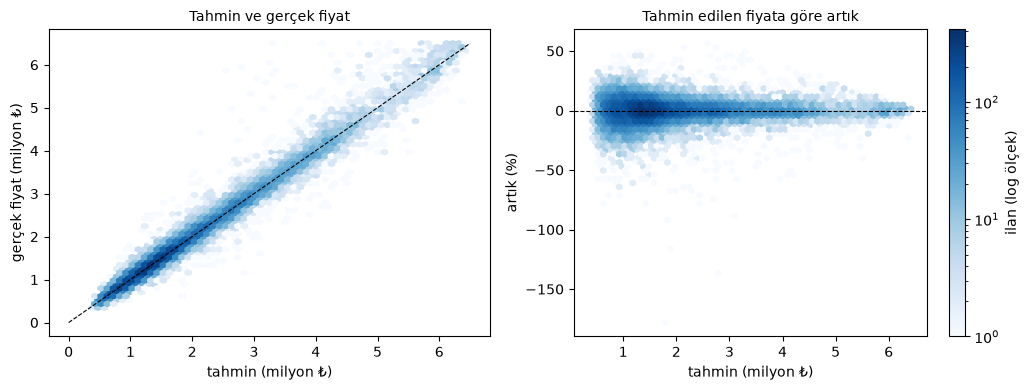

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].hexbin(pred / 1e6, price / 1e6, gridsize=60, bins="log", cmap="Blues", mincnt=1)
highest = max(pred.max(), price.max()) / 1e6
axes[0].plot([0, highest], [0, highest], "k--", lw=0.8)
axes[0].set(xlabel="tahmin (milyon ₺)", ylabel="gerçek fiyat (milyon ₺)")
axes[0].set_title("Tahmin ve gerçek fiyat", fontsize=10)
image = axes[1].hexbin(pred / 1e6, resid, gridsize=60, bins="log", cmap="Blues", mincnt=1)
axes[1].axhline(0, color="black", ls="--", lw=0.8)
axes[1].set(xlabel="tahmin (milyon ₺)", ylabel="artık (%)")
axes[1].set_title("Tahmin edilen fiyata göre artık", fontsize=10)
fig.colorbar(image, ax=axes[1], label="ilan (log ölçek)")
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Noktalar tahmin = gerçek çizgisinin çevresinde toplanıyor; pahalı uçta da çizgiden bir yöne
ayrılmıyorlar. Artığın ortalaması sıfıra çok yakın. Yüzde olarak yayılım ucuz tahminlerde geniş, pahalılarda dar.
Birkaç ilanın artığı çok eksi: tahmin ilan fiyatının iki katını aşıyor. Log fiyattaki R² ₺ fiyattakinden biraz düşük:
₺ R²'sini pahalı ilanlar belirliyor, log R²'sinde ucuz ilanların yüzde hatası da aynı ağırlıkta sayılıyor.

### 1.2 Hata bantları

|artık| dört banda ayrılıyor: %5'e kadar, %5–10, %10–20 ve %20'nin üstü (büyük hata). Her bantta ilan sayısı ve payı;
altında artığın medyanı, |artığın| medyanı ve ortalaması (ortalama |artık| 3. defterin MAPE'si), %10 içinde kalan
ilanların payı ve artığın en küçük ve en büyük değeri.

In [5]:
BANDS_TR = {"0_5": "%5'e kadar", "5_10": "%5–10", "10_20": "%10–20", "20_plus": "%20'nin üstü"}
abs_resid = np.abs(resid)
error_band = pd.cut(abs_resid, [0, 5, 10, 20, np.inf], include_lowest=True, labels=list(BANDS_TR))
bands = pd.Series(error_band).value_counts().reindex(list(BANDS_TR)).to_frame("n")
bands["share"] = 100 * bands["n"] / len(resid)

bands.round(2).rename(index=BANDS_TR, columns={"n": "ilan", "share": "pay (%)"}).rename_axis("|artık|")

,ilan,pay (%)
|artık|,,
%5'e kadar,15775,52.60
%5–10,8221,27.41
%10–20,4784,15.95
%20'nin üstü,1208,4.03


In [6]:
spread = pd.Series({"median": np.median(resid), "abs_median": np.median(abs_resid), "abs_mean": abs_resid.mean(),
                    "within_10": 100 * (abs_resid <= 10).mean(), "min": resid.min(), "max": resid.max()})

spread.round(2).rename({"median": "artığın medyanı (%)", "abs_median": "|artık| medyanı (%)",
                        "abs_mean": "|artık| ortalaması (%, MAPE)", "within_10": "|artık| ≤ %10 olan ilan (%)",
                        "min": "en küçük artık (%)", "max": "en büyük artık (%)"}).to_frame("değer")

,değer
artığın medyanı (%),-0.27
|artık| medyanı (%),4.68
"|artık| ortalaması (%, MAPE)",6.49
|artık| ≤ %10 olan ilan (%),80.02
en küçük artık (%),-178.08
en büyük artık (%),56.45


**%20 tanımı iki yönde eşit değil.** Artık gerçek fiyata bölünüyor. Fazla tahminde büyük hata, tahminin gerçek
fiyatın 1,2 katını aşması (artık < −%20); eksik tahminde ise tahminin gerçek fiyatın 0,8 katının altına düşmesi
(artık > %20), yani gerçek fiyatın tahminin 1,25 katını aşması. Eksik tahmin büyük hata sayılmak için daha uzağa
düşmek zorunda. İki yönün sayısı bu yüzden yalnız tanımla değil, yönü eşit tutan bir oranla da sayılıyor: tahmin
gerçeğin 1,2 katından büyük ya da gerçek tahminin 1,2 katından büyük.

In [7]:
large = errors.large_error(resid)
over, under = large & (resid < 0), large & (resid > 0)
directions = pd.DataFrame({"over": [over.sum(), (pred / price > 1.2).sum()],
                           "under": [under.sum(), (price / pred > 1.2).sum()]},
                          index=["pct_20", "ratio_1_2"])

directions.rename(index={"pct_20": "|artık| > %20 tanımıyla", "ratio_1_2": "1,2 kat, iki yönde aynı"}, columns={
    "over": "fazla tahmin (ilan)", "under": "eksik tahmin (ilan)"}).rename_axis("sayım")

,fazla tahmin (ilan),eksik tahmin (ilan)
sayım,,
|artık| > %20 tanımıyla,768,440
"1,2 kat, iki yönde aynı",768,812


**Ne görüyoruz.** İlanların yarısından fazlasında hata %5'in, beşte dördünde %10'un altında; %20'yi aşan ilanlar küçük
bir pay. Ortalama |artık| medyandan belirgin büyük: az sayıda büyük hata ortalamayı çekiyor. En küçük artık en
büyüğünden çok daha uzakta, çünkü artık gerçek fiyata bölünüyor: eksik tahminde artık %100'ü aşamaz, fazla tahminin
sınırı yok. %20 tanımıyla fazla tahmin eksik tahminden belirgin sık görünüyor; iki yönü aynı oranla sayınca eksik
tahmin fazla tahminden biraz sık. "Tahmin modeli fazla tahmine eğilimli" okuması tanımdan geliyor, veriden değil.

### 1.3 Fiyat düzeyine göre

İlanlar tahmin edilen fiyatın çeyreklerine bölünüyor (sınırlar yazdırılıyor). Her çeyrekte: ilan sayısı, |artığın|
medyanı, toplam ₺ hatasının (|gerçek − tahmin| toplamı) bu çeyreğe düşen payı, ortalama |₺ hata|, ₺ artığın ortalaması
ve medyanı. ₺ artık gerçek − tahmin: artı değer tahminin ilan fiyatının altında kaldığı demek.

In [8]:
QUARTERS = ["Q1", "Q2", "Q3", "Q4"]
QUARTERS_TR = {"Q1": "1. çeyrek (en ucuz)", "Q2": "2. çeyrek", "Q3": "3. çeyrek", "Q4": "4. çeyrek (en pahalı)"}
quarter_bounds = np.quantile(pred, [0.25, 0.5, 0.75])
quarter = pd.qcut(pred, 4, labels=QUARTERS).astype(str)
print("Çeyrek sınırları (₺):", [int(round(b)) for b in quarter_bounds])

gap = price - pred
by_quarter = pd.DataFrame({"quarter": quarter, "abs_resid": abs_resid, "gap": gap, "abs_gap": np.abs(gap)}).groupby(
    "quarter").agg(n=("gap", "size"), median_abs_resid=("abs_resid", "median"), lira_sum=("abs_gap", "sum"),
                   mean_abs_gap=("abs_gap", "mean"), mean_gap=("gap", "mean"), median_gap=("gap", "median"))
by_quarter.insert(2, "lira_share", 100 * by_quarter.pop("lira_sum") / np.abs(gap).sum())

by_quarter.round({"median_abs_resid": 2, "lira_share": 1, "mean_abs_gap": 0, "mean_gap": 0, "median_gap": 0}).astype(
    {"mean_abs_gap": int, "mean_gap": int, "median_gap": int}).rename(index=QUARTERS_TR, columns={
        "n": "ilan", "median_abs_resid": "|artık| medyanı (%)", "lira_share": "₺ hatasının payı (%)",
        "mean_abs_gap": "ortalama |₺ hata|", "mean_gap": "₺ artık ortalaması", "median_gap": "₺ artık medyanı"}
).rename_axis("tahmin çeyreği")

Çeyrek sınırları (₺): [1154371, 1532722, 2256098]


,ilan,|artık| medyanı (%),₺ hatasının payı (%),ortalama |₺ hata|,₺ artık ortalaması,₺ artık medyanı
tahmin çeyreği,,,,,,
1. çeyrek (en ucuz),7497,6.95,17.6,77305,4996,-1421
2. çeyrek,7497,4.97,19.9,87321,4763,-2889
3. çeyrek,7497,4.20,23.6,103608,3055,-6371
4. çeyrek (en pahalı),7497,3.55,38.9,170870,11872,-8863


Kalibrasyon doğrusu: gerçek fiyat = a + b · tahmin, en küçük kareler. b = 1 ve a = 0, tahminin ortalamada ne
yukarı ne aşağı kaydığı demek.

In [9]:
slope, intercept = np.polyfit(pred, price, 1)
print(f"Eğim b: {slope:.4f} | sabit a: {intercept:,.0f} ₺")

Eğim b: 1.0033 | sabit a: 86 ₺


**Ne görüyoruz.** Yüzde hata ucuzdan pahalıya düzenli küçülüyor: |artık| medyanı en ucuz çeyrekte en büyük. ₺ olarak
tersi: ortalama |₺ hata| en pahalı çeyrekte en büyük ve toplam ₺ hatasının en büyük payı orada. ₺ artığın ortalaması
her çeyrekte artıda, medyanı her çeyrekte ekside. Tipik ilanda tahmin fiyatın biraz üstünde; fiyatın tahminin üstünde
kaldığı ilanlarda ise fark ₺ olarak daha büyük (log ölçekte aynı hata yukarıda daha çok ₺ eder; 2.4) ve ortalamayı
artıya çekiyor. İki işaret birbiriyle çelişmiyor, aynı dağılımın iki özeti. Kalibrasyon doğrusunun eğimi 1'e çok
yakın, sabiti fiyatların yanında yok denecek kadar küçük: tahminler fiyat düzeyine göre ortalamada bir yöne kaymıyor.
Değişen, yayılım: aynı yüzde payın ucuz araçta daha az, pahalı araçta daha çok ilanı kapsaması bundan (3. bölüm).

## 2. Büyük hatalar

**Soru.** |artığı| %20'yi aşan ilanlar hangi ilanlar? Bu bölümün tabloları tek tek kırılımlar: bir kırılımdaki fark
başka bir kırılımın (ör. emsal sayısının) farkını da taşıyabilir. 2.3 bunu emsal sayısıyla birlikte gösteriyor.

### 2.1 Kaç büyük hata var

In [10]:
print(f"Büyük hata: {large.sum()} ilan (%{100 * large.mean():.2f}) | fazla tahmin {over.sum()}, eksik tahmin "
      f"{under.sum()}")

Büyük hata: 1208 ilan (%4.03) | fazla tahmin 768, eksik tahmin 440


### 2.2 Emsal

Bir ilanın hücresi, aynı araç modeli ve aynı model yılındaki bütün ilanlar (ilanın kendisi dahil, 3. defter 2.3'teki
sayım). Hücre büyüklüğünün kovalarında büyük hata oranı, fazla ve eksik tahmine ayrılmış:

In [11]:
SIZE_BINS = {"1": "1 (emsalsiz)", "2_4": "2–4", "5_19": "5–19", "20_99": "20–99", "100_plus": "100 ve üstü"}
SIZE_EDGES = [0, 1, 4, 19, 99, np.inf]
cell_size = listings.groupby(["model", "gb_year"])["price"].transform("size").to_numpy()
size_bin = pd.cut(cell_size, SIZE_EDGES, labels=list(SIZE_BINS)).astype(str)

flags = pd.DataFrame({"bin": size_bin, "large": large, "over": over, "under": under})
by_cell = flags.groupby("bin").agg(n=("large", "size"), large_pct=("large", "mean"), over_pct=("over", "mean"),
                                   under_pct=("under", "mean")).reindex(list(SIZE_BINS))
by_cell[["large_pct", "over_pct", "under_pct"]] *= 100

by_cell.round(2).rename(index=SIZE_BINS, columns={"n": "ilan", "large_pct": "büyük hata (%)", "over_pct": "fazla (%)",
                                                  "under_pct": "eksik (%)"}).rename_axis("hücredeki ilan")

,ilan,büyük hata (%),fazla (%),eksik (%)
hücredeki ilan,,,,
1 (emsalsiz),610,19.02,10.66,8.36
2–4,1584,10.48,6.19,4.29
5–19,5732,4.73,3.02,1.71
20–99,16505,2.99,1.94,1.05
100 ve üstü,5557,2.90,2.02,0.88


Aynı soru araç modeli düzeyinde: her araç modelinin ilan sayısı ve ilanlarının |artık| medyanı. Grafikte her araç
modeli bir nokta; çizgi, ilan sayısı kovalarında bu medyanların medyanı. Tablo kovaları sayıyor.

In [12]:
per_model = pd.DataFrame({"model": listings["model"].to_numpy(), "abs_resid": abs_resid}).groupby("model")[
    "abs_resid"].agg(n="size", median="median")
per_model["bin"] = pd.cut(per_model["n"], SIZE_EDGES, labels=list(SIZE_BINS)).astype(str)
model_buckets = per_model.groupby("bin").agg(models=("n", "size"), listings=("n", "sum"),
                                             median_of_medians=("median", "median")).reindex(list(SIZE_BINS))
print("En az 5 ilanlı araç modeli:", int((per_model["n"] >= 5).sum()), "/", len(per_model))

model_buckets.round(2).rename(index=SIZE_BINS, columns={
    "models": "araç modeli", "listings": "ilan", "median_of_medians": "medyan |artık| medyanı (%)"}).rename_axis(
    "araç modelinin ilanı")

En az 5 ilanlı araç modeli: 438 / 745


,araç modeli,ilan,medyan |artık| medyanı (%)
araç modelinin ilanı,,,
1 (emsalsiz),126,126,8.89
2–4,181,506,8.47
5–19,188,1876,5.99
20–99,171,7946,4.71
100 ve üstü,79,19534,4.58


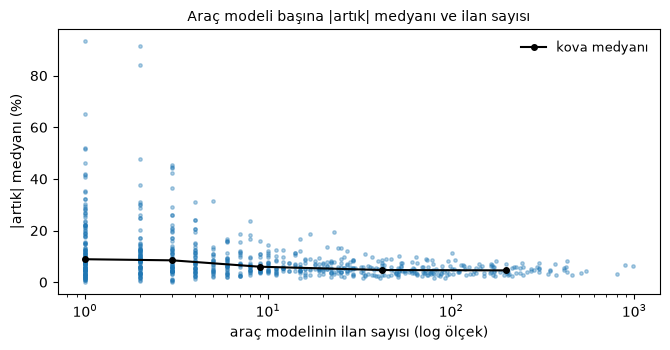

In [13]:
centres = per_model.groupby("bin")["n"].median().reindex(list(SIZE_BINS))
fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.scatter(per_model["n"], per_model["median"], s=6, alpha=0.35)
ax.plot(centres, model_buckets["median_of_medians"], "o-", color="black", ms=4, label="kova medyanı")
ax.set_xscale("log")
ax.set(xlabel="araç modelinin ilan sayısı (log ölçek)", ylabel="|artık| medyanı (%)")
ax.set_title("Araç modeli başına |artık| medyanı ve ilan sayısı", fontsize=10)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Büyük hata emsal azaldıkça sıklaşıyor: emsalsiz ilanlarda oran en yüksek, hücresi 20 ve üstü ilanlı
olanlarda en düşük ve oradan sonra bir daha düşmüyor. Fazla ve eksik tahmin aynı eğilimde. Araç modeli düzeyinde de
aynı tablo: az ilanlı araç modellerinin medyan hatası yüksek ve çok dağınık, 20 ve üstü ilanlılarınki düşük ve
birbirine yakın. Tahmin modeli az görülmüş bir aracı, adı benzeyen araç modellerinden bilgi ödünç alsa da (3. defter,
1.2), belirgin daha çok yanılıyor.

### 2.3 Yaş ve segment

Büyük hata oranı her yaşta (grafik) ve her kesim noktasında: t yaş ve üstü ile t yaşın altı, ve ikisinin oranı
(tablo, t = 8 … en büyük yaş). Oran düzgün değişiyorsa tek bir kesim noktası (ör. 18) "sert bir kırılma" diye
okunmamalı.

In [14]:
age = listings["vehicle_age"].to_numpy()
by_age = pd.DataFrame({"age": age, "large": large}).groupby("age")["large"].agg(n="size", pct="mean")
by_age["pct"] *= 100

cuts = {}
for t in range(8, int(age.max()) + 1):
    older, younger = large[age >= t].mean(), large[age < t].mean()
    cuts[t] = {"n_older": (age >= t).sum(), "older_pct": 100 * older, "younger_pct": 100 * younger,
               "ratio": older / younger}
cuts = pd.DataFrame(cuts).T

cuts.round(2).astype({"n_older": int}).rename(columns={
    "n_older": "t ve üstü (ilan)", "older_pct": "t ve üstü (%)", "younger_pct": "t altı (%)", "ratio": "oran"}
).rename_axis("t (yaş)")

,t ve üstü (ilan),t ve üstü (%),t altı (%),oran
t (yaş),,,,
8,22919,5.04,0.75,6.72
9,21754,5.19,0.95,5.48
10,19680,5.52,1.17,4.71
11,16608,6.26,1.26,4.95
12,13382,7.14,1.52,4.71
13,10655,7.97,1.86,4.29
14,8482,9.01,2.06,4.36
15,5816,10.28,2.52,4.07
16,3997,11.38,2.90,3.93


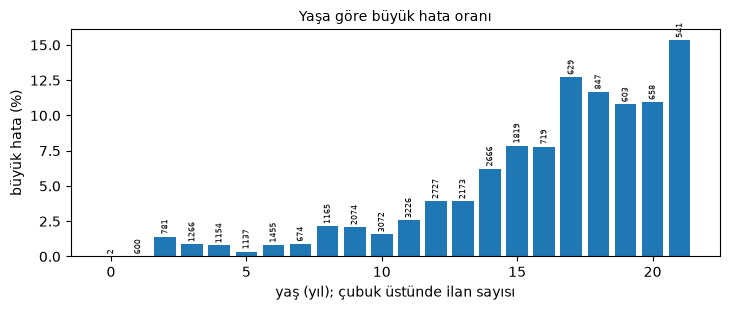

In [15]:
fig, ax = plt.subplots(figsize=(7.4, 3.2))
ax.bar(by_age.index, by_age["pct"], width=0.8)
for a, row in by_age.iterrows():
    ax.text(a, row["pct"] + 0.3, int(row["n"]), ha="center", fontsize=6, rotation=90)
ax.set(xlabel="yaş (yıl); çubuk üstünde ilan sayısı", ylabel="büyük hata (%)")
ax.set_title("Yaşa göre büyük hata oranı", fontsize=10)
fig.tight_layout()
plt.show()

F ve S segmenti (en pahalı ve spor sınıf) ile öteki segmentler:

In [16]:
OLD_AGE = 18
groups_2_3 = {"age_18_plus": age >= OLD_AGE, "age_under_18": age < OLD_AGE,
              "segment_f_s": listings["segment"].isin(["F", "S"]).to_numpy()}
groups_2_3["segment_other"] = ~groups_2_3["segment_f_s"]
GROUPS_2_3_TR = {"age_18_plus": "18 yaş ve üstü", "age_under_18": "18 yaşın altı", "segment_f_s": "F ya da S segmenti",
                 "segment_other": "öteki segmentler"}

pd.DataFrame({name: {"n": mask.sum(), "large_pct": 100 * large[mask].mean()} for name, mask in groups_2_3.items()}
             ).T.round(2).astype({"n": int}).rename(index=GROUPS_2_3_TR, columns={"n": "ilan",
                                                                                 "large_pct": "büyük hata (%)"})

,ilan,büyük hata (%)
18 yaş ve üstü,2649,12.04
18 yaşın altı,27339,3.25
F ya da S segmenti,444,19.14
öteki segmentler,29544,3.80


Yaşlı araçların ve F/S segmentinin emsali de daha az. Aynı oranlar hücre büyüklüğünün kovaları içinde: bir kovada iki
grubun oranı birbirine yaklaşıyorsa yukarıdaki farkın bir kısmı emsal farkıdır. Hücresi 30'dan az ilanlı gruplar boş.

In [17]:
MIN_SHOWN = 30
within = {}
for name, mask in groups_2_3.items():
    part = flags[mask].groupby("bin")["large"].agg(["size", "mean"]).reindex(list(SIZE_BINS))
    within[name] = (100 * part["mean"]).where(part["size"] >= MIN_SHOWN)
within = pd.DataFrame(within)
within.insert(0, "n_f_s", flags[groups_2_3["segment_f_s"]].groupby("bin").size().reindex(list(SIZE_BINS)).fillna(0))

within.round(2).astype({"n_f_s": int}).rename(index=SIZE_BINS, columns={"n_f_s": "F/S ilanı", **{
    name: f"{label} (%)" for name, label in GROUPS_2_3_TR.items()}}).rename_axis("hücredeki ilan")

,F/S ilanı,18 yaş ve üstü (%),18 yaşın altı (%),F ya da S segmenti (%),öteki segmentler (%)
hücredeki ilan,,,,,
1 (emsalsiz),64,34.34,16.05,43.75,16.12
2–4,148,20.27,8.23,18.92,9.61
5–19,232,13.41,3.73,12.50,4.40
20–99,0,8.95,2.37,NaN,2.99
100 ve üstü,0,5.94,2.84,NaN,2.90


**Ne görüyoruz.** Büyük hata yaşla düzenli artıyor; orta yaşlardan sonra hızlanıyor. Kesim tablosunda oran (t ve üstü
/ t altı) t büyüdükçe önce azalıyor, sonra hemen hemen sabit kalıyor; 18'de ya da başka bir yaşta bir sıçrama yok,
yani tek bir kesim noktası "kırılma" diye okunmamalı. F ve S segmentinde büyük hata öteki segmentlerin birkaç katı.
İki grup da emsalce fakir: F/S ilanlarının hepsi 20'den az ilanlı hücrelerde. Hücre kovaları içinde yaşlı araçların
oranı her kovada belirgin yüksek kalıyor; F/S'nin farkı kovalar içinde daralıyor ama kapanmıyor, gruplar da küçük.
Yaşlı araç aynı zamanda ucuz ve çok km'li, F/S aracı pahalı; bu tablolar yaşın ya da segmentin payını bunlardan
ayırmıyor. Söylenebilen şu: bu ilanlarda büyük hata sık. "F/S ayrı bir etken" ya da "yaş tek başına hatayı büyütüyor"
diye okunmamalı.

### 2.4 En büyük ₺ hataları

Yüzde hatada her ilan eşit; ₺ hatasında pahalı ilanlar ağır basar. En büyük 100 ₺ hatası (|gerçek − tahmin|): kaçı
eksik, kaçı fazla tahmin; kaçının tahmini en pahalı çeyrekte; kaçı segmenti araç modeli adından çözülen ilanlardan
(M, RS ve S aileleri ile i8 ve Z4 M; 2. defter, 2.1).

In [18]:
TOP_N = 100
top = errors.top_lira(price, pred, TOP_N)
from_name = np.array([data.resolve_segment(s, m)[1] != "series_map" for s, m in zip(listings["series"],
                                                                                    listings["model"])])
q4 = quarter == "Q4"
ranking = pd.Series({"under": (price[top] > pred[top]).sum(), "over": (price[top] < pred[top]).sum(),
                     "q4": q4[top].sum(), "from_name": from_name[top].sum()})
print("Segmenti adından çözülen ilanlar: bütün ilanlarda %", round(100 * from_name.mean(), 2),
      "| 4. çeyrekte %", round(100 * from_name[q4].mean(), 2), "| seriler:", sorted(set(listings["series"][from_name])))

ranking.rename({"under": "eksik tahmin", "over": "fazla tahmin", "q4": "tahmini 4. çeyrekte",
                "from_name": "segmenti adından çözülen"}).to_frame(f"en büyük {TOP_N} ₺ hatası içinde")

Segmenti adından çözülen ilanlar: bütün ilanlarda % 0.52 | 4. çeyrekte % 1.83 | seriler: ['M Serisi', 'RS', 'S', 'i Serisi']


,en büyük 100 ₺ hatası içinde
eksik tahmin,73
fazla tahmin,27
tahmini 4. çeyrekte,84
segmenti adından çözülen,23


En büyük ₺ hatalarının çoğunun eksik tahmin olması kendi başına bir bulgu değil. Log ölçekte aynı büyüklükteki hata,
fiyat tahminin üstündeyken ₺ olarak daha büyüktür: e^0,2 − 1 > 1 − e^−0,2. Karşılaştırma: her ilan kendi log hatasını
tutar, işareti yazı turayla seçilir ve en büyük 100 ₺ hatası yeniden seçilir (`errors.symmetric_under_counts`, 200
çekiliş, tohum 42). Log hata simetrik olsaydı en büyük 100'ün kaçı eksik tahmin olurdu?

In [19]:
SEED = 42
symmetric = errors.symmetric_under_counts(price, pred, TOP_N, n_draws=200, seed=SEED)
print(f"Simetrik log hatayla eksik tahmin: ortalama {symmetric.mean():.1f}, %95 aralık "
      f"{np.percentile(symmetric, 2.5):.0f}–{np.percentile(symmetric, 97.5):.0f} | gözlenen {ranking['under']}")

Simetrik log hatayla eksik tahmin: ortalama 67.8, %95 aralık 60–77 | gözlenen 73


**Ne görüyoruz.** En büyük 100 ₺ hatasının çoğu eksik tahmin ve çoğunun tahmini en pahalı çeyrekte. Ama log hata
simetrik olsaydı da en büyük 100'ün çoğu eksik tahmin olurdu ve gözlenen sayı bu karşılaştırmanın aralığının içinde:
büyük ₺ hatalarının eksik tahminde toplanması ₺ ölçeğinin sonucu, tahmin modelinin pahalı araçta bir yöne kaydığının
işareti değil (1.3'teki kalibrasyon doğrusu da bunu söylüyor). Segmenti araç modeli adından çözülen ilanlar bütün
ilanların da en pahalı çeyreğin de küçük bir kısmı, ama en büyük 100 ₺ hatası içinde belirgin daha sık. Bu sıklığı
tek bir "kaç kat" sayısına çevirmek yanıltır: sayı, hangi grupla karşılaştırıldığına (bütün ilanlar, en pahalı çeyrek)
göre çok değişiyor.

### 2.5 Motor tutarlılık kuralı

2. defterin motor tutarlılık kuralı (`spec_rule.spec_outliers`; 2. defter, 5.9): gücü ya da hacmi kendi araç
modelinin medyanından 1,5 kattan fazla sapan ilan işaretlenir, en az 5 ilanı olan araç modellerinde. Böyle bir değer
çoğunlukla katalog eşleşmesinin hatası: ilana aracın sahip olmadığı bir motor yazılmış, tahmin modeli de o motoru
fiyatlıyor. İşaretli ilanların |artık| medyanı ötekilerle; kuralın sınayamadığı ilanlar (araç modelinin 5'ten az
ilanı var) ayrıca sayılıyor.

In [20]:
spec_off, blind = (mask.to_numpy() for mask in spec_rule.spec_outliers(listings))
spec_table = pd.Series({"flagged": spec_off.sum(), "flagged_pct": 100 * spec_off.mean(),
                        "flagged_median": np.median(abs_resid[spec_off]),
                        "other_median": np.median(abs_resid[~spec_off]), "flagged_large": large[spec_off].sum(),
                        "blind": blind.sum(), "blind_pct": 100 * blind.mean(),
                        "blind_models": listings.loc[blind, "model"].nunique()})

spec_table.round(2).rename({"flagged": "işaretli ilan", "flagged_pct": "işaretli ilan (%)",
                            "flagged_median": "işaretlilerde |artık| medyanı (%)",
                            "other_median": "ötekilerde |artık| medyanı (%)",
                            "flagged_large": "işaretlilerde büyük hata", "blind": "sınanamayan ilan",
                            "blind_pct": "sınanamayan ilan (%)", "blind_models": "sınanamayan araç modeli"}).to_frame(
    "değer")

,değer
işaretli ilan,15.00
işaretli ilan (%),0.05
işaretlilerde |artık| medyanı (%),12.79
ötekilerde |artık| medyanı (%),4.68
işaretlilerde büyük hata,6.00
sınanamayan ilan,632.00
sınanamayan ilan (%),2.11
sınanamayan araç modeli,307.00


**Ne görüyoruz.** Kural çok az ilanı işaretliyor. İşaretli ilanların |artık| medyanı ötekilerin birkaç katı ve
önemli bir kısmı büyük hata: katalogda yanlış motor yazılmış ilanı tahmin modeli o motorla fiyatlıyor. Bu, büyük
hataların küçük ama açıklanabilir bir kaynağı. Kuralın kör noktası işaretli ilanlardan çok daha büyük: araç modelinin
5'ten az ilanı varsa kural sınanamıyor, ve bu ilanlar zaten emsali az, büyük hatanın sık olduğu ilanlar (2.2).

## 3. %90 aralık

**Soru.** Tahminin etrafına ne kadar pay konmalı ki gerçek fiyat ilanların %90'ında içinde kalsın, ve bu %90 her tür
araçta tutuyor mu?

Aralık log ölçekte kurulur: [expm1(log tahmin − r), expm1(log tahmin + r)], r yarı genişlik (`interval.interval`;
alt uç 0'ın, üst uç 15 milyon ₺'nin dışına çıkmaz). Log ölçekte simetrik aralık ₺'de simetrik değil: r = 0,1 aşağı
yaklaşık %9,5, yukarı %10,5 demek. **Kapsama** gerçek fiyatı aralığın içinde kalan ilanların payı.

**Çapraz kalibrasyon.** r, bilinen hataların bir yüzdeliğinden gelir. Bir ilanın kendi hatası kendi aralığını
belirlerse kapsama iyimser ölçülür. Bu yüzden her katın ilanlarına r yalnız öteki dört katın kat dışı hatalarından
kurulur. Yüzdelik sonlu örneklem yüzdeliği (`interval.conformal_quantile`): n hatanın en küçükten
ceil((n + 1) · 0,9)'uncusu.

### 3.1 Tek pay

İlk kol herkese aynı payı verir: her kat için öteki dört katın log hatalarının %90 yüzdeliği
(`interval.cross_single_q`). Ölçek modelinden önce servis edilen aralık buydu; o zaman bütün ilanların log
hatalarından tek bir q kuruluyordu (son satır, sıradan %90 yüzdeliği).

In [21]:
q_single = interval.cross_single_q(log_err, fold)
q_served_before = float(np.quantile(log_err, interval.LEVEL))
single_q = pd.Series({k: q_single[fold == k][0] for k in range(1, folds.N_FOLDS + 1)}).rename(lambda k: f"{k}. kat")
single_q["bütün ilanlar"] = q_served_before

single_q.to_frame("q").assign(lower_pct=lambda t: 100 * np.expm1(-t["q"]), upper_pct=lambda t: 100 * np.expm1(t["q"])
                              ).round(4).rename(columns={"lower_pct": "alt pay (%)", "upper_pct": "üst pay (%)"})

,q,alt pay (%),üst pay (%)
1. kat,0.1406,-13.1126,15.0915
2. kat,0.1408,-13.1363,15.1228
3. kat,0.1414,-13.1896,15.1935
4. kat,0.1410,-13.1475,15.1377
5. kat,0.1421,-13.2478,15.2708
bütün ilanlar,0.1412,-13.1710,15.1689


### 3.2 Ölçek modeli

Tek pay yeni ve emsali bol bir araca da, eski ve emsalsiz bir araca da aynı payı verir. **Ölçek modeli** payı araca
göre ayarlar: r = k · s(x).

- **s(x)** bu tür bir araçta beklenen log hata. Küçük bir LightGBM, ilanın kat dışı log hatasını tahmin eder
  (`interval.fit_scale`). Girdisi tahmin modelinin metin dışı kodlu matrisi (dokuz kategorik ve on dört sayısal kolon;
  araç modeli ve seri adının SVD kolonları yok), log tahmin ve emsal sayısı (`interval.scale_matrices`). Emsal
  arttıkça s artamaz (monotonluk kısıtı: "daha çok emsal payı hiç genişletmez"); s 0,02'nin altına inmez.
- **Emsal sayısı** burada ilanın kendi katı sayılmadan sayılır (`interval.other_fold_counts`): aynı araç modeli ve
  model yılındaki ilanlardan öteki katlarda olanlar. İlanın kat dışı hatasını kendi katını görmemiş bir tahmin modeli
  üretti; emsali de öyle sayılır.
- **k** iç içe skorların (hata / s) %90 yüzdeliği; skoru veren s o ilanın katını hiç görmemiştir
  (`interval.nested_scale`).

Ayarlar bir kez kondu ve aranmadı:

In [22]:
SCALE_NOTES = {"n_estimators": "ağaç sayısı (sabit, erken durdurma yok)", "learning_rate": "her ağacın katkı oranı",
               "num_leaves": "bir ağacın en çok yaprak sayısı", "min_child_samples": "bir yaprakta en az kaç ilan",
               "subsample": "her ağaçta kullanılan ilan payı", "subsample_freq": "ilan payı her ağaçta yeniden çekilir",
               "colsample_bytree": "her ağaçta kullanılan kolon payı", "random_state": "tohum",
               "verbose": "LightGBM'in kendi iletileri kapalı", "deterministic": "aynı girdi ve ayarla aynı ağaçlar",
               "force_row_wise": "deterministic'in çok iş parçacığında da tutması için",
               "n_jobs": "iş parçacığı sayısı"}

settings = pd.DataFrame({"value": pd.Series(interval.SCALE_PARAMS).astype(str), "note": pd.Series(SCALE_NOTES)})
settings.loc["s_floor"] = [str(interval.S_FLOOR), "s'nin alt sınırı (log puan)"]
settings.loc["monotone"] = ["emsal: −1", "emsal arttıkça s artamaz"]
settings.rename_axis("ayar").rename(columns={"value": "değer", "note": "ne"})

,değer,ne
ayar,,
n_estimators,300,"ağaç sayısı (sabit, erken durdurma yok)"
learning_rate,0.05,her ağacın katkı oranı
num_leaves,15,bir ağacın en çok yaprak sayısı
min_child_samples,100,bir yaprakta en az kaç ilan
subsample,0.8,her ağaçta kullanılan ilan payı
subsample_freq,1,ilan payı her ağaçta yeniden çekilir
colsample_bytree,0.8,her ağaçta kullanılan kolon payı
random_state,42,tohum
verbose,-1,LightGBM'in kendi iletileri kapalı


**Çapraz kalibreli ölçek kolu** (`interval.cross_scale`). Puanlanan bir kat için hem s hem k yalnız öteki dört kattan
gelir. s, o dört katın hatalarıyla eğitilir. k için o dört katın her biri, kalan üç katla eğitilmiş bir s ile
puanlanır ve bu skorların %90 yüzdeliği alınır. Böylece 5 + 20 küçük model eğitilir; puanlanan katın hatası hiçbirine
girmez. Aynı skorlar isabet olasılığını da verir (4. bölüm). Önbellekten:

In [23]:
cells = listings["model"].astype(str) + "|" + listings["gb_year"].astype(str)
comparables = interval.other_fold_counts(cells, fold)
scale = cache.load_or_run(interval.cross_scale, model_table, log_err, log_pred, comparables, fold)
r_scale = scale["r"]
k_all = interval.conformal_quantile(scale["scores"])

print("Puanlanan kat başına k:", [round(k, 4) for k in scale["k_by_fold"]])
print(f"Bütün iç içe skorlardan k: {k_all:.4f} | s alt sınırda olan ilan: {int((scale['s'] <= interval.S_FLOOR).sum())}"
      f" | en küçük s: {scale['s'].min():.4f}")

Puanlanan kat başına k: [2.0898, 2.0878, 2.0859, 2.0962, 2.1048]
Bütün iç içe skorlardan k: 2.0874 | s alt sınırda olan ilan: 0 | en küçük s: 0.0214


### 3.3 İki kol yan yana

Her kol için kapsama, aralık genişliğinin (tahminin yüzdesi olarak) medyanı ve ortalaması, aralık skoru ve emsalsiz
ilanlarda kapsama. **Aralık skoru** (`interval.interval_score`, log ölçekte) genişlik artı dışarıda kalan fiyatın
uzaklığının 20 katı; küçük olan iyi. Dar ama sık kaçıran bir aralık da, geniş ama hep tutan bir aralık da bu skorda
kaybeder. Son iki kolon fiyatın aralığın üstünde ve altında kaldığı ilanların payı.

In [24]:
ARMS_TR = {"single": "tek pay", "scale": "ölçek modeli"}
ARM_COLUMNS = {"coverage": "kapsama (%)", "width_median": "genişlik medyanı (%)",
               "width_mean": "genişlik ortalaması (%)", "interval_score": "aralık skoru",
               "coverage_no_comparable": "emsalsizde kapsama (%)", "missed_above": "üstte kalan (%)",
               "missed_below": "altta kalan (%)"}
no_comparable = comparables == 0
arms = pd.DataFrame({name: interval.arm_summary(price, pred, r, no_comparable)
                     for name, r in {"single": q_single, "scale": r_scale}.items()}).T
print("Emsalsiz ilan (öteki katlarda aynı hücrede ilan yok):", int(no_comparable.sum()))

arms.round({"coverage": 2, "width_median": 1, "width_mean": 1, "interval_score": 4, "coverage_no_comparable": 2,
            "missed_above": 2, "missed_below": 2}).rename(index=ARMS_TR, columns=ARM_COLUMNS).rename_axis("kol")

Emsalsiz ilan (öteki katlarda aynı hücrede ilan yok): 752


,kapsama (%),genişlik medyanı (%),genişlik ortalaması (%),aralık skoru,emsalsizde kapsama (%),üstte kalan (%),altta kalan (%)
kol,,,,,,,
tek pay,89.99,28.3,28.3,0.4211,70.74,5.16,4.86
ölçek modeli,90.09,24.7,27.2,0.3657,90.29,5.41,4.50


Aynı kapsama tahmin çeyreklerinde (1.3'teki çeyrekler) ve emsal kovalarında; çeyreklerde genişliğin medyanı da:

In [25]:
COMP_BINS = {"0": "0", "1_4": "1–4", "5_19": "5–19", "20_plus": "20 ve üstü"}
comp_bin = pd.cut(comparables, [-1, 0, 4, 19, np.inf], labels=list(COMP_BINS)).astype(str)
covered = {"single": interval.inside(price, pred, q_single), "scale": interval.inside(price, pred, r_scale)}
widths = {"single": interval.width_pct(pred, q_single), "scale": interval.width_pct(pred, r_scale)}

frame = pd.DataFrame({"quarter": quarter, "comp": comp_bin, **{f"cov_{a}": 100 * covered[a] for a in ARMS_TR},
                      **{f"width_{a}": widths[a] for a in ARMS_TR}})
cov_quarter = frame.groupby("quarter").agg(n=("cov_single", "size"), cov_single=("cov_single", "mean"),
                                           cov_scale=("cov_scale", "mean"), width_single=("width_single", "median"),
                                           width_scale=("width_scale", "median"))
cov_comp = frame.groupby("comp").agg(n=("cov_single", "size"), cov_single=("cov_single", "mean"),
                                     cov_scale=("cov_scale", "mean")).reindex(list(COMP_BINS))
COV_COLUMNS = {"n": "ilan", "cov_single": "tek pay: kapsama (%)", "cov_scale": "ölçek: kapsama (%)",
               "width_single": "tek pay: genişlik medyanı (%)", "width_scale": "ölçek: genişlik medyanı (%)"}

display(cov_quarter.round(2).rename(index=QUARTERS_TR, columns=COV_COLUMNS).rename_axis("tahmin çeyreği"))
cov_comp.round(2).rename(index=COMP_BINS, columns=COV_COLUMNS).rename_axis("emsal (öteki katlarda)")

,ilan,tek pay: kapsama (%),ölçek: kapsama (%),tek pay: genişlik medyanı (%),ölçek: genişlik medyanı (%)
tahmin çeyreği,,,,,
1. çeyrek (en ucuz),7497,80.99,89.94,28.29,35.68
2. çeyrek,7497,90.98,90.16,28.29,25.77
3. çeyrek,7497,93.25,89.56,28.29,20.86
4. çeyrek (en pahalı),7497,94.72,90.72,28.29,16.73


,ilan,tek pay: kapsama (%),ölçek: kapsama (%)
emsal (öteki katlarda),,,
0,752,70.74,90.29
1–4,2403,82.36,90.47
5–19,6752,89.20,89.44
20 ve üstü,20081,91.88,90.26


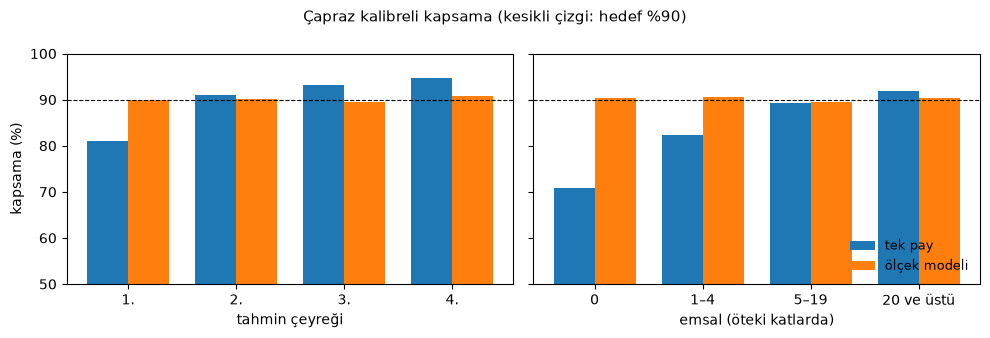

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, table, labels, title in [(axes[0], cov_quarter, [f"{i}." for i in range(1, 5)], "tahmin çeyreği"),
                                 (axes[1], cov_comp, list(COMP_BINS.values()), "emsal (öteki katlarda)")]:
    positions = np.arange(len(table))
    for i, arm in enumerate(ARMS_TR):
        ax.bar(positions + (i - 0.5) * 0.38, table[f"cov_{arm}"], width=0.38, label=ARMS_TR[arm])
    ax.axhline(100 * interval.LEVEL, color="black", ls="--", lw=0.8)
    ax.set_xticks(positions, labels)
    ax.set_xlabel(title)
    ax.set_ylim(50, 100)
axes[0].set_ylabel("kapsama (%)")
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Çapraz kalibreli kapsama (kesikli çizgi: hedef %90)", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** İki kol da bütün ilanlarda hedefte. Tek pay herkese aynı genişliği verdiği için en ucuz çeyrekte ve
emsalsiz ilanlarda belirgin kaçırıyor, pahalı çeyrekte ve bol emsalli ilanlarda gereğinden geniş. Ölçek modeli her
çeyrekte ve her emsal kovasında hedefe yakın; aralığı ucuz çeyrekte geniş, pahalı çeyrekte dar. Medyan aralığı tek
paydan dar, ortalaması tek payınkine yakın: aralıkların çoğu dar, bir kısmı geniş. Aralık skorunda ölçek modeli
belirgin iyi. Bütün ilanlarda %90 çıkması çapraz kalibrasyonda beklenen sonuç, çünkü katlar rastgele; asıl sınama
gruplarda (3.4) ve sonradan gelen ilanlarda (6).

### 3.4 Gruplarda kapsama

Kapsama iki tür eksende, en az 200 ilanlı her grupta ölçülüyor:

- **s'nin girdisi olan eksenler**: yaş kovaları, km ve güç beşte birleri (gücü boş ilanlar en alt beşte birde),
  segment, yakıt, vites, kasa tipi, ağır hasar kaydı, değişen parça sayısı ve serinin ilan sayısı. Ölçek modeli bu
  bilgiyi gördüğü için bu eksenlerde düzelme kısmen tasarım gereği; yine de kat dışında ölçülüyor, ve tahmin modeline
  verilen bilgiye göre doğru kapsama tam da istenen şey.
- **s'nin görmediği eksenler**: satıcı tipi, il (en büyük sekiz il, kalanı birlikte), renk, garanti, ilk sahip, takas
  ve hasar kaydı tutarı. Boş değer kendi grubu (`missing`).

Özet: girdi eksenlerinde hedeften (%90) 5 puan ya da daha çok sapan grup sayısı ve en büyük sapma; görülmeyen
eksenlerde kolun kendi genel kapsamasının 3 puan ya da daha çok altında kalan grup sayısı ve en kötü grup.

In [27]:
MIN_GROUP = 200


def fifths(values):
    """Değerlerin beşte biri (0 en küçük); boş değer -1 sayılır, eşitler satır sırasıyla ayrılır."""
    return pd.qcut(values.fillna(-1).rank(method="first"), 5, labels=False).astype(str)


def labelled(values):
    """Bir kolonun değerleri metin olarak; boş değer 'missing'."""
    return values.astype("string").fillna("missing").astype(str)


series_n = listings["series"].map(listings["series"].value_counts())
city = listings["location"].astype(str).str.split(",").str[-1].str.strip()
input_axes = {"age": pd.cut(listings["vehicle_age"], [-1, 3, 7, 12, 18, 25, 99]).astype(str),
              "mileage": fifths(listings["gb_mileage"]), "power": fifths(listings["power_hp_val"]),
              "segment": listings["segment"], "fuel": listings["kb_fuel"], "transmission": listings["kb_transmission"],
              "body_type": listings["kb_body_type"], "heavy_damage": labelled(listings["is_heavy_damaged"]),
              "changed_parts": pd.cut(listings["count_changed"].fillna(0), [-1, 0, 1, 3, 99]).astype(str),
              "series_listings": pd.cut(series_n, [0, 20, 100, 500, np.inf]).astype(str)}
unseen_axes = {"seller_type": labelled(listings["kb_seller_type"]),
               "city": city.where(city.isin(city.value_counts().index[:8]), "rest"),
               "colour": labelled(listings["kb_color"]), "warranty": labelled(listings["gb_warranty_status"]),
               "first_owner": labelled(listings["gb_is_first_owner"]),
               "trade_in": labelled(listings["kb_trade_available"]),
               "damage_record": pd.cut(listings["tramer_fee"].fillna(-1), [-2, -0.5, 0, 20_000, 100_000, np.inf]
                                       ).astype(str)}


def group_coverage(axes_):
    """Her eksenin en az MIN_GROUP ilanlı her grubunda iki kolun kapsaması (%); (eksen, grup) satırlı tablo."""
    out = {}
    for axis, groups in axes_.items():
        groups = np.asarray(groups, dtype=str)
        for value in pd.unique(groups):
            mask = groups == value
            if mask.sum() >= MIN_GROUP:
                out[axis, value] = {"n": mask.sum(), **{arm: 100 * covered[arm][mask].mean() for arm in ARMS_TR}}
    return pd.DataFrame(out).T


AXIS_TR = {"age": "yaş", "mileage": "km beşte biri", "power": "güç beşte biri", "segment": "segment", "fuel": "yakıt",
           "transmission": "vites", "body_type": "kasa tipi", "heavy_damage": "ağır hasar kaydı",
           "changed_parts": "değişen parça", "series_listings": "serinin ilanı", "seller_type": "satıcı tipi",
           "city": "il", "colour": "renk", "warranty": "garanti", "first_owner": "ilk sahip", "trade_in": "takas",
           "damage_record": "hasar kaydı tutarı"}
VALUE_TR = {"True": "evet", "False": "hayır", "missing": "boş", "rest": "öteki iller"}   # yalnız gösterim için

in_groups, out_groups = group_coverage(input_axes), group_coverage(unseen_axes)
axis_summary, worst_group = {}, {}
for arm in ARMS_TR:
    deviation = (in_groups[arm] - 100 * interval.LEVEL).abs()
    below = out_groups[arm] - arms.loc[arm, "coverage"]
    worst_group[arm] = below.idxmin()
    axis, value = worst_group[arm]
    axis_summary[arm] = {"input_groups": len(in_groups), "input_off_5": (deviation >= 5).sum(),
                         "input_max_dev": deviation.max(), "unseen_groups": len(out_groups),
                         "unseen_below_3": (below <= -3).sum(),
                         "unseen_worst": f"{AXIS_TR[axis]}: {VALUE_TR.get(value, value)}",
                         "unseen_worst_n": int(out_groups.loc[worst_group[arm], "n"]), "unseen_worst_gap": below.min()}
axis_summary = pd.DataFrame(axis_summary).T.infer_objects()

axis_summary.rename(index=ARMS_TR, columns={
    "input_groups": "girdi: grup", "input_off_5": "girdi: 5 puan ve üstü sapan",
    "input_max_dev": "girdi: en büyük sapma", "unseen_groups": "görülmeyen: grup",
    "unseen_below_3": "görülmeyen: 3 puan ve üstü altta", "unseen_worst": "görülmeyen: en kötü grup",
    "unseen_worst_n": "en kötü grubun ilanı", "unseen_worst_gap": "en kötü grubun farkı (puan)"}).rename_axis(
    "kol").round(1)

,girdi: grup,girdi: 5 puan ve üstü sapan,girdi: en büyük sapma,görülmeyen: grup,görülmeyen: 3 puan ve üstü altta,görülmeyen: en kötü grup,en kötü grubun ilanı,en kötü grubun farkı (puan)
kol,,,,,,,,
tek pay,42,18,25.2,34,6,renk: Gri (Gümüş),315,-10.3
ölçek modeli,42,0,3.5,34,4,ilk sahip: evet,302,-5.7


Bütün gruplar tek grafikte: her satır bir eksen, her nokta bir grup.

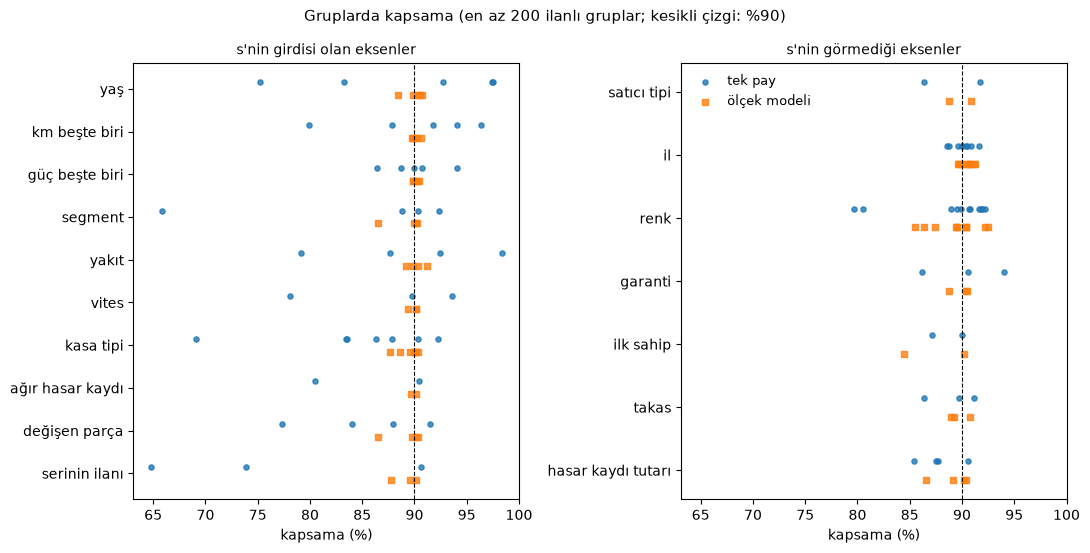

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharex=True)
for ax, groups, title in [(axes[0], in_groups, "s'nin girdisi olan eksenler"),
                          (axes[1], out_groups, "s'nin görmediği eksenler")]:
    names = list(dict.fromkeys(groups.index.get_level_values(0)))
    axis_row = np.array([names.index(axis) for axis in groups.index.get_level_values(0)])
    for offset, arm, marker in [(-0.15, "single", "o"), (0.15, "scale", "s")]:
        ax.scatter(groups[arm], axis_row + offset, s=14, marker=marker, label=ARMS_TR[arm], alpha=0.8)
    ax.axvline(100 * interval.LEVEL, color="black", ls="--", lw=0.8)
    ax.set_yticks(range(len(names)), [AXIS_TR[name] for name in names])
    ax.invert_yaxis()
    ax.set_xlabel("kapsama (%)")
    ax.set_title(title, fontsize=10)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle(f"Gruplarda kapsama (en az {MIN_GROUP} ilanlı gruplar; kesikli çizgi: %90)", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Girdi eksenlerinde tek payın gruplarının önemli bir kısmı hedeften 5 puandan fazla sapıyor: yeni,
km'si az ve hibrit araçlarda aralık gereğinden geniş; yaşlı, km'si çok, LPG'li, düz vitesli, F segmentli, ağır hasar
kayıtlı, çok parçası değişmiş ve az ilanlı serilerdeki araçlarda dar. Ölçek modelinde bu eksenlerin hiçbir grubu 5
puandan fazla sapmıyor; en uzak gruplar F segmenti ve çok parçası değişmiş araçlar, ikisi de küçük. Bu düzelmenin bir
kısmı tasarım gereği: s bu bilgiyi görüyor. s'nin görmediği eksenlerde iki kol arasında açık bir fark yok: ikisinde de
birkaç grup kendi genel kapsamasının 3 puandan fazla altında. En kötü grup tek payda bir renk (gümüş gri), ölçek
modelinde ilk sahibinden araçlar; ikisi de küçük ve otuzdan fazla grup arasından seçilmiş, rastlantı olabilir. Garanti
ve takas bilgisi boş ilanlar tek payda hedefin altında kalıyor, ölçek modelinde kalmıyor. s'nin bilmediği bir bilgi
(satıcı, il, renk, ilandaki bir kusur) aralığı düzeltemez; ölçek modeli bu eksenlerde tek paydan ne iyi ne kötü.

### 3.5 Payın dağılımı

Ölçek modelinin aralığı ilandan ilana değişiyor. Genişliğin (tahminin yüzdesi) ve alt ve üst payın yüzdelikleri;
altında en dar aralık ve aralığı tek paydan dar olan ilanların payı. En geniş aralık yazdırılmıyor: tek bir ilana ve
ölçek modelinin ayarına çok bağlı; %99 yüzdeliği okunuyor.

In [29]:
WIDTH_PCTS = [5, 25, 50, 75, 95, 99]
width_scale = widths["scale"]
width_table = pd.DataFrame({q: {"width": np.percentile(width_scale, q),
                                "lower": 100 * np.expm1(-np.percentile(r_scale, q)),
                                "upper": 100 * np.expm1(np.percentile(r_scale, q))} for q in WIDTH_PCTS}).T
narrower_pct = 100 * (r_scale < q_single).mean()
print(f"En dar aralık: %{width_scale.min():.1f} | aralığı tek paydan dar ilan: %{narrower_pct:.2f}")

width_table.round(1).rename(columns={"width": "genişlik (%)", "lower": "alt pay (%)", "upper": "üst pay (%)"}
                            ).rename_axis("yüzdelik")

En dar aralık: %8.9 | aralığı tek paydan dar ilan: %62.44


,genişlik (%),alt pay (%),üst pay (%)
yüzdelik,,,
5,14.4,-7.0,7.5
25,18.4,-8.8,9.6
50,24.7,-11.6,13.1
75,33.0,-15.2,17.9
95,47.9,-21.1,26.8
99,68.3,-28.5,39.8


s emsal sayısına nasıl bağlı? Bütün ilanlarla eğitilmiş ölçek modelinde (5. bölümdeki servis edilen s) her ilanın
emsal sayısı aynı değere konuyor ve s'nin ilanlar üzerindeki ortalaması alınıyor (kısmi bağımlılık). Bu ölçek modeli
bütün ilanların hatasıyla eğitiliyor (`interval.fit_scale_all`); önbellekten:

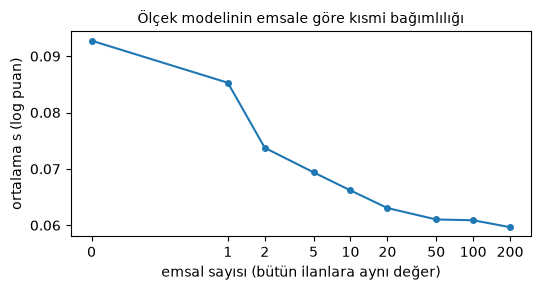

emsal,0,1,2,5,10,20,50,100,200
ortalama s,0.0928,0.0853,0.0737,0.0694,0.0662,0.0631,0.061,0.0609,0.0597


In [30]:
served_scale = cache.load_or_run(interval.fit_scale_all, model_table, log_err, log_pred, comparables)
every_row = np.arange(len(model_table))
X_scale_all, _, _ = interval.scale_matrices(model_table, every_row, every_row, log_pred, comparables)
PD_GRID = [0, 1, 2, 5, 10, 20, 50, 100, 200]
dependence = pd.Series({g: interval.predict_scale(served_scale, X_scale_all.assign(**{interval.COMPARABLES: g})).mean()
                        for g in PD_GRID})

fig, ax = plt.subplots(figsize=(5.6, 3))
ax.plot(dependence.index, dependence, "o-", ms=4)
ax.set_xscale("symlog", linthresh=1)
ax.set_xticks(PD_GRID, [str(g) for g in PD_GRID])
ax.set(xlabel="emsal sayısı (bütün ilanlara aynı değer)", ylabel="ortalama s (log puan)")
ax.set_title("Ölçek modelinin emsale göre kısmi bağımlılığı", fontsize=10)
fig.tight_layout()
plt.show()
dependence.round(4).rename_axis("emsal").rename("ortalama s").to_frame().T

**Ne görüyoruz.** İlanların çoğunda aralık tek paydan dar. Payın ortası tek payın biraz altında, dağılımın üst ucu ise
uzun: en geniş birkaç yüzde ilanda aralık tahminin yarısını aşıyor. Alt pay her yüzdelikte üst paydan küçük: log
ölçekte simetrik aralık ₺'de yukarı doğru uzun. s emsal arttıkça azalıyor; ilk birkaç emsalde hızlı, 20 emsalden sonra
neredeyse düz. Monotonluk kısıtı yalnız yönü sabitliyor, eğrinin biçimi veriden geliyor.

### 3.6 Araç türüne göre

Araç türü başına iki kolun kapsaması, ölçek modelinin payı (grubun medyan yarı genişliğinden, %) ve grubun medyan
tahmini etrafında iki kolun aralığı (bin ₺'ye yuvarlanmış). Son iki kolon isabet olasılığının öngörülen ortalaması ve
gerçekleşen payı (4. bölüm).

In [31]:
hit = log_err <= np.log1p(interval.WITHIN)
top_km = pd.qcut(listings["gb_mileage"].rank(method="first"), 5, labels=False).to_numpy() == 4
PROFILES = {"all": np.ones(len(price), dtype=bool), "age_0_3": age <= 3, "age_4_7": (age >= 4) & (age <= 7),
            "age_8_12": (age >= 8) & (age <= 12), "age_13_18": (age >= 13) & (age <= 18), "age_19_plus": age >= 19,
            "no_comparable": no_comparable, "comparables_20_plus": comparables >= 20,
            "cheapest_quarter": quarter == "Q1", "dearest_quarter": quarter == "Q4", "top_mileage_fifth": top_km,
            "heavy_damaged": listings["is_heavy_damaged"].to_numpy() == 1,
            "segment_f": listings["segment"].to_numpy() == "F"}
PROFILES_TR = {"all": "bütün ilanlar", "age_0_3": "0–3 yaş", "age_4_7": "4–7 yaş", "age_8_12": "8–12 yaş",
               "age_13_18": "13–18 yaş", "age_19_plus": "19 yaş ve üstü", "no_comparable": "emsalsiz",
               "comparables_20_plus": "20 ve üstü emsal", "cheapest_quarter": "en ucuz çeyrek",
               "dearest_quarter": "en pahalı çeyrek", "top_mileage_fifth": "km'si en yüksek beşte bir",
               "heavy_damaged": "ağır hasar kayıtlı", "segment_f": "F segmenti"}

profiles = {}
for name, mask in PROFILES.items():
    centre, r_mid, q_mid = np.median(pred[mask]), np.median(r_scale[mask]), np.median(q_single[mask])
    profiles[name] = {"n": mask.sum(), "cov_single": 100 * covered["single"][mask].mean(),
                      "cov_scale": 100 * covered["scale"][mask].mean(), "lower_pct": 100 * np.expm1(-r_mid),
                      "upper_pct": 100 * np.expm1(r_mid),
                      "single_low": centre * np.exp(-q_mid), "single_high": centre * np.exp(q_mid),
                      "scale_low": centre * np.exp(-r_mid), "scale_high": centre * np.exp(r_mid),
                      "hit_predicted": 100 * scale["p"][mask].mean(), "hit_observed": 100 * hit[mask].mean()}
profiles = pd.DataFrame(profiles).T
TL_PROFILE = ["single_low", "single_high", "scale_low", "scale_high"]

shown_profiles = profiles.round({"cov_single": 1, "cov_scale": 1, "lower_pct": 1, "upper_pct": 1, "hit_predicted": 1,
                                 "hit_observed": 1})
shown_profiles[TL_PROFILE] = (profiles[TL_PROFILE] / 1e3).round().astype(int)
shown_profiles.astype({"n": int}).rename(index=PROFILES_TR, columns={
    "n": "ilan", "cov_single": "tek pay: kapsama (%)", "cov_scale": "ölçek: kapsama (%)",
    "lower_pct": "ölçek: alt pay (%)", "upper_pct": "ölçek: üst pay (%)", "single_low": "tek pay: alt (bin ₺)",
    "single_high": "tek pay: üst (bin ₺)", "scale_low": "ölçek: alt (bin ₺)", "scale_high": "ölçek: üst (bin ₺)",
    "hit_predicted": "isabet: öngörülen (%)", "hit_observed": "isabet: gerçekleşen (%)"}).rename_axis("araç türü")

,ilan,tek pay: kapsama (%),ölçek: kapsama (%),ölçek: alt pay (%),ölçek: üst pay (%),tek pay: alt (bin ₺),tek pay: üst (bin ₺),ölçek: alt (bin ₺),ölçek: üst (bin ₺),isabet: öngörülen (%),isabet: gerçekleşen (%)
araç türü,,,,,,,,,,,
bütün ilanlar,29988,90.0,90.1,-11.6,13.1,1331,1765,1355,1734,78.3,78.3
0–3 yaş,2649,97.4,90.8,-7.5,8.1,3415,4527,3636,4252,92.1,92.3
4–7 yaş,4420,97.5,90.5,-7.4,8.0,2360,3128,2516,2933,91.7,92.1
8–12 yaş,12264,92.7,89.9,-10.5,11.7,1380,1829,1422,1775,81.7,81.6
13–18 yaş,8853,83.3,90.3,-15.2,17.9,959,1271,936,1302,67.0,66.5
19 yaş ve üstü,1802,75.2,88.5,-18.1,22.1,603,799,568,847,58.5,58.9
emsalsiz,752,70.7,90.3,-19.7,24.6,1491,1977,1378,2139,53.1,55.6
20 ve üstü emsal,20081,91.9,90.3,-10.8,12.1,1304,1728,1339,1682,81.2,80.9
en ucuz çeyrek,7497,81.0,89.9,-16.3,19.4,788,1044,760,1083,64.7,64.0


**Ne görüyoruz.** Tek payın kapsaması araç türüne göre geniş bir aralığa yayılıyor: yeni araçlarda hedefin çok
üstünde; yaşlı, emsalsiz, ucuz, km'si yüksek, ağır hasar kayıtlı araçlarda ve F segmentinde belirgin altında. Ölçek
modeli bunların hepsinde hedefe yakın; en uzak olan F segmenti, küçük bir grup. Bunu payı araca göre değiştirerek
yapıyor: yeni ve pahalı araçta pay daralıyor, yaşlı ve emsalsiz araçta genişliyor; aralık da (bin ₺) buna göre
kayıyor. İsabet olasılığının öngörülen ortalaması her araç türünde gerçekleşen paya yakın, en çok birkaç puan uzak.

### 3.7 Fiyat seviyesi kayarsa

Kapsama bu verinin fiyatlarıyla ölçüldü. Bir varsayım hesabı: bütün ilan fiyatları %2, %5 ya da %10 yüksek olsaydı
kapsama ne olurdu? Tahminler ve aralıklar aynı kalıyor, yalnız fiyatlar kaydırılıyor. Bu bir zaman analizi değil:
veriye dokunmuyor, yalnız seviyenin etkisini gösteriyor; seviye kaymasının ne kadar olacağını da söylemiyor. İki kolun
kapsaması bütün ilanlarda ve ölçek modelinin aralığı en dar beşte bir ilanda; son kolon gerçekleşen ±%10 isabet payı.

In [32]:
SHIFTS = [0, 2, 5, 10]
narrow = pd.qcut(pd.Series(r_scale).rank(method="first"), 5, labels=False).to_numpy() == 0
shifted = {}
for shift in SHIFTS:
    moved = price * (1 + shift / 100)
    inside_single, inside_scale = interval.inside(moved, pred, q_single), interval.inside(moved, pred, r_scale)
    shifted[shift] = {"single": 100 * inside_single.mean(), "scale": 100 * inside_scale.mean(),
                      "narrow_single": 100 * inside_single[narrow].mean(),
                      "narrow_scale": 100 * inside_scale[narrow].mean(),
                      "hit": 100 * (np.abs(np.log1p(moved) - log_pred) <= np.log1p(interval.WITHIN)).mean()}
shifted = pd.DataFrame(shifted).T

shifted.round(2).rename(columns={"single": "tek pay (%)", "scale": "ölçek (%)",
                                 "narrow_single": "en dar beşte bir: tek pay (%)",
                                 "narrow_scale": "en dar beşte bir: ölçek (%)", "hit": "±%10 isabet (%)"}).rename_axis(
    "fiyat kayması (%)")

,tek pay (%),ölçek (%),en dar beşte bir: tek pay (%),en dar beşte bir: ölçek (%),±%10 isabet (%)
fiyat kayması (%),,,,,
0,89.99,90.09,98.85,90.55,78.27
2,89.22,88.56,98.37,86.96,77.13
5,86.13,82.35,96.45,73.59,70.58
10,73.89,61.57,84.79,33.69,49.37


**Ne görüyoruz.** Fiyatlar yükselirse kapsama iki kolda da düşüyor; ölçek modelinde daha hızlı, en hızlı da ölçek
modelinin en dar aralıklarında. Tek payın aynı ilanlardaki aralığı bol olduğu için kaymayı uzun süre karşılıyor.
**Dar aralık önce eskir**: ölçek modelinin keskinliğinin bedeli bu. ±%10 isabet de kaymayla düşüyor. Tablo kaymanın
olup olmayacağını ya da ne kadar olacağını söylemiyor; sonradan gelen ilanlardaki durum 6. bölümde.

## 4. İsabet olasılığı

**Soru.** Aralığın yanında daha kolay okunan bir sayı: bu tür bir araçta ilan fiyatının tahminin ±%10 yakınında olma
olasılığı. Bu olasılık güvenilir mi?

**Tanım.** İsabet, log hatanın log(1,1)'i aşmaması (fiyat tahminin kabaca ±%10 yakınında). Olasılık ölçek modelinin
aynı iç içe skorlarından: bir ilanın s'si için, skorlardan log(1,1) / s'in altında ya da ona eşit olanların payı
(`interval.p_within`). Çapraz kalibreli kolda bu skorlar da puanlanan katı görmemiş (3.2). Ayrı bir model yok;
tolerans (±%10) bir kez kondu, aranmadı.

**Güvenilirlik** (`interval.reliability`): ilanlar öngörülen olasılığa göre onda birlik dilimlere bölünür; her dilimde
ortalama öngörülen olasılık ile gerçekleşen isabet payı yan yana. İkisi örtüşüyorsa olasılık kalibre. **Brier skoru**
öngörü ile gerçekleşen (0 ya da 1) arasındaki farkın karesinin ortalaması; küçük olan iyi. Karşılaştırma herkese genel
isabet payını veren sabit öngörü; iyileşme, Brier skorunun bu sabit öngörüye göre yüzde düşüşü.

In [33]:
reliability = interval.reliability(scale["p"], hit)
confidence = pd.Series({"mean_predicted": reliability["mean_predicted"], "mean_observed": reliability["mean_observed"],
                        "brier": reliability["brier"], "brier_constant": reliability["brier_constant"],
                        "skill_pct": reliability["skill_pct"],
                        **{f"p{q}": value for q, value in reliability["quantiles"].items()}})

confidence.round(4).rename({"mean_predicted": "ortalama öngörülen (%)", "mean_observed": "gerçekleşen (%)",
                            "brier": "Brier skoru", "brier_constant": "sabit öngörünün Brier skoru",
                            "skill_pct": "Brier iyileşmesi (%)", "p10": "öngörünün %10'luk yüzdeliği (%)",
                            "p50": "öngörünün medyanı (%)", "p90": "öngörünün %90'lık yüzdeliği (%)"}).to_frame("değer")

,değer
ortalama öngörülen (%),78.3489
gerçekleşen (%),78.2680
Brier skoru,0.1493
sabit öngörünün Brier skoru,0.1701
Brier iyileşmesi (%),12.2118
öngörünün %10'luk yüzdeliği (%),57.8787
öngörünün medyanı (%),80.8299
öngörünün %90'lık yüzdeliği (%),95.3899


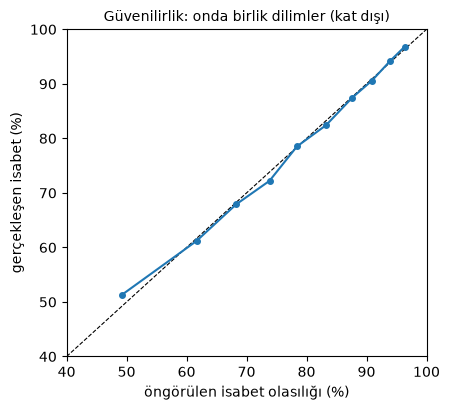

In [34]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
deciles = reliability["deciles"]
ax.plot([40, 100], [40, 100], "k--", lw=0.8)
ax.plot(deciles["predicted"], deciles["observed"], "o-", ms=4)
ax.set(xlabel="öngörülen isabet olasılığı (%)", ylabel="gerçekleşen isabet (%)", xlim=(40, 100), ylim=(40, 100))
ax.set_title("Güvenilirlik: onda birlik dilimler (kat dışı)", fontsize=10)
fig.tight_layout()
plt.show()

Olasılık kısaca "10'da N" diye de okunabilir: N = 10 · olasılık aşağı yuvarlanır ve en çok 9 olur (`interval.shown`),
çünkü hiçbir araçta isabet kesin değil. Her N değerinde ilan sayısı ve gerçekleşen isabet:

In [35]:
reliability["by_shown"].round(1).astype({"n": int}).rename(columns={"n": "ilan", "observed": "gerçekleşen (%)"}
                                                         ).rename_axis("10'da N")

,ilan,gerçekleşen (%)
10'da N,,
1,7,14.3
2,106,30.2
3,280,40.4
4,868,48.8
5,2506,57.1
6,4637,64.4
7,6118,74.7
8,6983,84.8
9,8483,94.2


**Ne görüyoruz.** Öngörülen ve gerçekleşen her dilimde birbirine yakın, noktalar köşegenin üstünde: olasılık kat
dışında kalibre, ortalama öngörü gerçekleşen payla aynı. Olasılık araçları da ayırıyor: en alt dilimle en üst dilim
arasında büyük fark var ve Brier skoru herkese aynı olasılığı veren öngörüden iyi. "10'da N" gösteriminde gerçekleşen
isabet N büyüdükçe düzenli artıyor ve her N'de N/10'un üstünde: aşağı yuvarlama ihtiyatlı yönde. Bu kalibrasyon aynı
dönemin ilanlarında ölçüldü; sonradan gelen ilanlarda 6.3'te.

## 5. Servis edilen aralık

**Soru.** Servis edilen tahmin modeli bir araca aralığı ve isabet olasılığını nasıl veriyor?

Tarif 3. ve 4. bölümdekiyle aynı; tek fark, s'nin ve emsalin bütün ilanlardan gelmesi:

- **Tahmin:** 3. defterin son tahmin modeli (`model.fit_final`, bütün ilanlarla); log tahmin 0 ile 15 milyon ₺
  arasına kırpılır.
- **s:** bütün ilanların kat dışı hatasıyla eğitilmiş ölçek modeli (`interval.fit_scale_all`, 3.5'teki); kategori
  kodları bütün ilanlardan, son tahmin modelininkilerle aynı. Eğitimde emsal ilanın kendi katı sayılmadan sayılmıştı.
- **k ve isabet olasılığının skorları:** 3.2'deki bütün iç içe skorlardan (her ilanı kendi katını görmemiş bir s
  puanlar).
- **Emsal tablosu:** her (araç modeli, yaş) hücresindeki ilan sayısı; araç modeli adı birebir aranır, bulunamazsa
  emsal 0. Defterin geri kalanı emsali (araç modeli, model yılı) ile sayıyor; bütün ilanlar aynı yılın taramalarından
  geldiği için iki hücreleme aynı (`tests/lib/test_interval.py` sınıyor).

In [36]:
comparable_counts = listings.groupby(["model", "vehicle_age"]).size()
counts = {(str(m), int(a)): int(n) for (m, a), n in comparable_counts.items()}
sorted_scores = np.sort(scale["scores"])
served = pd.Series({"k": round(k_all, 4), "s_floor": interval.S_FLOOR, "within_pct": round(100 * interval.WITHIN),
                    "n_scores": len(sorted_scores), "cells": len(counts), "listings": sum(counts.values()),
                    "data_until": listings["snap"].max()})

served.rename({"k": "k", "s_floor": "s'nin alt sınırı", "within_pct": "isabet toleransı (±%)",
               "n_scores": "skor sayısı", "cells": "emsal tablosunda hücre", "listings": "emsal tablosundaki ilan",
               "data_until": "verinin son taraması"}).to_frame("değer")

,değer
k,2.0874
s'nin alt sınırı,0.02
isabet toleransı (±%),10
skor sayısı,29988
emsal tablosunda hücre,2194
emsal tablosundaki ilan,29988
verinin son taraması,2026-06-27


**İşlenmiş örnekler.** `interval.served_examples` tarifi bir araca uygular: araç tahmin modelinin matrisine çevrilir
(kodlar ve TF-IDF + SVD ilanlardan; görülmemiş kategori −1), tahmin edilir, emsal tablodan aranır, s ve isabet
olasılığı hesaplanır. Dört araç; ilki gerçek bir ilan, öteki üçü ondan türetilmiş uydurma girdiler:

- **bol emsalli**: en az 100 ilanlı (araç modeli, yaş) hücrelerinde son tahmin modelinin tahmini en yüksek ilan;
- **emsalsiz**: aynı araç, araç modelinin hiç görülmediği en yakın büyük yaşta;
- **ad bir harf eksik**: aynı araç, araç modeli adının son harfi düşmüş (emsal bulunamaz);
- **görülmemiş kategori**: aynı araç, yakıt kolonunda veride hiç görülmemiş bir değerle (kendi kasa tipinin adı).

Son tahmin modeli 3. defterin kaydından okunuyor (ağaç sayısı temel koşumun katlarının medyanı; 3. defter, 5):

In [37]:
base_trees = cache.load_or_run(model.oof_lightgbm, model_table, cv_folds)["trees"]
final = cache.load_or_run(model.fit_final, model_table, int(np.median(base_trees)))
X_final, _, _ = model.fold_matrices(model_table, every_row, every_row)
final_log = np.clip(final.predict(X_final), 0, np.log1p(errors.PRICE_CAP))
cell_n = np.array([counts[str(m), int(a)] for m, a in zip(listings["model"], listings["vehicle_age"])])
full_cells = np.flatnonzero(cell_n >= 100)
base_car = model_table.iloc[[full_cells[np.argmax(final_log[full_cells])]]][data.FEATURES].reset_index(drop=True)
seen_ages = {a for m, a in counts if m == base_car.at[0, "model"]}
older = next(a for a in range(int(base_car.at[0, "vehicle_age"]) + 1, 200) if a not in seen_ages)
if base_car.at[0, "kb_body_type"] in set(listings["kb_fuel"]):
    raise ValueError("örnek yakıt değeri veride görülmüş")
cars = pd.concat([base_car, base_car.assign(vehicle_age=float(older)),
                  base_car.assign(model=base_car["model"].str[:-1]), base_car.assign(kb_fuel=base_car["kb_body_type"])],
                 ignore_index=True)
cars.index = ["many_comparables", "no_comparable", "model_typo", "unseen_category"]

examples = interval.served_examples(final, served_scale, k_all, sorted_scores, model_table, cars, counts)
EXAMPLES_TR = {"many_comparables": "bol emsalli", "no_comparable": "emsalsiz", "model_typo": "ad bir harf eksik",
               "unseen_category": "görülmemiş kategori"}
examples.assign(price=examples["price"].round(-3).astype(int)).round(
    {"s": 4, "lower_pct": 1, "upper_pct": 1, "hit_pct": 1}).rename(index=EXAMPLES_TR, columns={
        "price": "tahmin (₺)", "comparables": "emsal", "s": "s", "lower_pct": "alt pay (%)", "upper_pct": "üst pay (%)",
        "hit_pct": "isabet olasılığı (%)", "shown": "10'da N"}).rename_axis("örnek")

,tahmin (₺),emsal,s,alt pay (%),üst pay (%),isabet olasılığı (%),10'da N
örnek,,,,,,,
bol emsalli,4820000,117,0.0463,-9.2,10.1,89.6,8
emsalsiz,2287000,0,0.1412,-25.5,34.3,42.9,4
ad bir harf eksik,4674000,0,0.0846,-16.2,19.3,65.1,6
görülmemiş kategori,4814000,117,0.0462,-9.2,10.1,89.7,8


**Ne görüyoruz.** Bol emsalli pahalı araçta pay dar ve isabet olasılığı yüksek. Aynı araç emsalsiz bir yaşta
verilince pay belirgin genişliyor ve isabet olasılığı yarının altına iniyor (tahmin de değişiyor, çünkü yaş
değişti). Araç modeli adı bir harf eksik yazılınca emsal bulunamıyor ve pay genişliyor: hata ihtiyatlı yönde, ama
nedeni araç değil addaki yazım; ad, eğitimdeki adla birebir aranıyor. Yakıt kolonunda görülmemiş bir değer (kod −1)
tahmini de payı da neredeyse değiştirmiyor.

## 6. İleri test

**Soru.** Şimdiye kadarki her sayı kat dışı: katlar rastgele, dört taramanın ilanları karışık. Tahmin modeli eskiden
öğrenip sonra gelen ilanı fiyatlarsa hata, aralık ve isabet ne olur?

**Kurulum** (`forward.split`). Eğitim: son taramadan önce görülen her ilan, o taramalardaki son satırıyla. Test: son
taramada ilk kez görülen ilanlar. Tahmin modeli servis edilen tahmin modeli gibi kurulur (`forward.forward_run`):
eğitim kümesinde beş katlı kat dışı koşum (3. defterin `model.oof_lightgbm`'i), ağaç sayısı katların medyanı, sonra
bütün eğitim kümesiyle tek eğitim (`forward.fit_predict`). Aralık da servis edilen tarifle, yalnız eğitim kümesinden:
tek pay eğitim kümesinin kat dışı log hatalarından; ölçek modelinin skorları ve k eğitim kümesinin iç içe
skorlarından, test ilanlarının s'si bütün eğitim kümesiyle eğitilen ölçek modelinden; test ilanının emsali eğitim
kümesinde aynı hücredeki ilan sayısı. Test taraması hiçbir şeyi belirlemez: ne tahmin modelini, ne ağaç sayısını, ne
q'yu, ne s'yi ya da k'yı; test ilanlarının fiyatı koşuma hiç verilmez.

Bu tek bir test: eğitimle test arasında tek bir zaman farkı var ve sonuç ona özgü. Tahmin modeli zamanı görmez;
taramaların fiyatları birlikte öğrenilir.

In [38]:
rows_all = data.add_features(data.load_rows(latest_only=False))
train, test, train_until, test_snap = forward.split(rows_all)
print(f"Eğitim: {train_until}'e kadarki taramalar, {len(train)} ilan | test: {test_snap} taramasında yeni "
      f"{len(test)} ilan")

Eğitim: 2026-03-21'e kadarki taramalar, 21099 ilan | test: 2026-06-27 taramasında yeni 8889 ilan


Ağır adım önbellekten:

In [39]:
def cell_of(frame):
    """İlan başına emsal hücresi: araç modeli ve model yılı."""
    return frame["model"].astype(str) + "|" + frame["gb_year"].astype(str)


ahead = cache.load_or_run(forward.forward_run, train[data.FEATURES + ["price"]], test[data.FEATURES], cell_of(train),
                          cell_of(test))
print("Eğitim kümesinin katlarında ağaç sayısı:", ahead["cv_trees"], "| medyan:", ahead["trees"])

Eğitim kümesinin katlarında ağaç sayısı: [209, 227, 226, 211, 203] | medyan: 211


### 6.1 Hata

Test ilanlarında MAPE ve %95 aralığı. Aralık küme bootstrap'iyle (`forward.cluster_bootstrap`, 1.000 çekiliş, tohum
42): araç modelleri yerine koyarak yeniden çekilir, çünkü aynı araç modelinin ilanları birbirinden bağımsız değil.
Aralığın kapsadığı belirsizlik test ilanlarının örneklenmesi; tahmin modelini yeniden kurmanın oynaması içinde değil.

Karşılaştırma aynı ilanlarda yapılmalı. Test ilanları ilan tablosunda da var (son satırları son taramada); temel
koşumun kat dışı tahminleri onlar için de var. İlk satır ileri test, ikinci satır aynı ilanların kat dışı hatası,
üçüncü satır ikisinin farkı (ilan başına fark, aynı çekilişlerle).

In [40]:
N_BOOT = 1000
test_price = test["price"].to_numpy(dtype=float)
forward_ape = np.abs(test_price - np.expm1(ahead["test_pred_log"])) / test_price * 100
position = pd.Series(np.arange(len(listings)), index=listings["ad_id"].to_numpy())
same = position.loc[test["ad_id"].to_numpy()].to_numpy()
oof_ape = np.abs(price[same] - oof["pred_price"].to_numpy()[same]) / price[same] * 100
draws = forward.cluster_bootstrap(test["model"], [forward_ape, oof_ape], n_boot=N_BOOT, seed=SEED)
draws = np.column_stack([draws, draws[:, 0] - draws[:, 1]])

mape_table = pd.DataFrame({"mape": [forward_ape.mean(), oof_ape.mean(), forward_ape.mean() - oof_ape.mean()],
                           "low": np.percentile(draws, 2.5, axis=0), "high": np.percentile(draws, 97.5, axis=0)},
                          index=["forward", "oof_same", "difference"])
mape_table.round(2).rename(index={"forward": "ileri test", "oof_same": "aynı ilanlar, kat dışı",
                                  "difference": "fark (ileri − kat dışı)"}, columns={
    "mape": "MAPE (%)", "low": "%95 alt", "high": "%95 üst"}).rename_axis("test ilanları")

,MAPE (%),%95 alt,%95 üst
test ilanları,,,
ileri test,6.78,6.42,7.17
"aynı ilanlar, kat dışı",6.60,6.22,7.01
fark (ileri − kat dışı),0.18,0.10,0.26


**Ne görüyoruz.** İleri testin MAPE'si temel koşumun bütün ilanlardaki MAPE'sinden (3. defter, 1.4) yüksek. Ama bu
farkın çoğu test ilanlarının kendisinden geliyor: aynı ilanların kat dışı hatası da bütün ilanlarınkinden yüksek.
İleri kuruluma özgü kısım, aynı ilanlarda ileri test eksi kat dışı, küçük ve aralığı sıfırı dışlıyor. Bu kısım iki
şeyi birlikte taşıyor: ileri kurulumda tahmin modeli son taramanın hiçbir ilanını görmüyor ve daha az ilanla
öğreniyor; taramalar arasında fiyatlar da oynamış olabilir. Tek test bunları birbirinden ayıramıyor.

### 6.2 Aralık

İki kol test ilanlarında, 3.3'teki ölçülerle. Eğitim kümesinden kurulan tek pay ve ölçek modelinin k'sı yazdırılıyor;
emsalsiz, (araç modeli, model yılı) hücresi eğitim kümesinde hiç olmayan test ilanı.

In [41]:
train_pred = np.clip(np.expm1(ahead["train_pred_log"]), 0, errors.PRICE_CAP)
train_log_err = np.abs(np.log1p(train["price"].to_numpy(dtype=float)) - np.log1p(train_pred))
q_forward = interval.conformal_quantile(train_log_err)
k_forward = interval.conformal_quantile(ahead["scores"])
test_pred = np.clip(np.expm1(ahead["test_pred_log"]), 0, errors.PRICE_CAP)
r_forward = {"single": np.full(len(test), q_forward), "scale": k_forward * ahead["test_s"]}
test_no_comparable = ahead["test_comparables"] == 0
print(f"Tek pay q: {q_forward:.4f} | ölçek k: {k_forward:.4f} | emsalsiz test ilanı: {int(test_no_comparable.sum())} | "
      f"s alt sınırda: {int((ahead['test_s'] <= interval.S_FLOOR).sum())}")

forward_arms = pd.DataFrame({arm: interval.arm_summary(test_price, test_pred, r, test_no_comparable)
                             for arm, r in r_forward.items()}).T
forward_arms.round({"coverage": 2, "width_median": 1, "width_mean": 1, "interval_score": 4,
                    "coverage_no_comparable": 2, "missed_above": 2, "missed_below": 2}).rename(
    index=ARMS_TR, columns=ARM_COLUMNS).rename_axis("kol")

Tek pay q: 0.1405 | ölçek k: 2.0997 | emsalsiz test ilanı: 297 | s alt sınırda: 2


,kapsama (%),genişlik medyanı (%),genişlik ortalaması (%),aralık skoru,emsalsizde kapsama (%),üstte kalan (%),altta kalan (%)
kol,,,,,,,
tek pay,87.40,28.2,28.2,0.4438,68.35,8.91,3.69
ölçek modeli,86.83,24.0,26.8,0.3977,88.55,10.47,2.70


Kapsama tahmin çeyreklerinde (sınırlar eğitim kümesinin kat dışı tahminlerinden) ve ölçek modelinin aralık
genişliğinin beşte birlerinde (1 en dar):

In [42]:
forward_bounds = np.quantile(train_pred, [0.25, 0.5, 0.75])
test_quarter = np.searchsorted(forward_bounds, test_pred, side="left")
test_fifth = pd.qcut(pd.Series(r_forward["scale"]).rank(method="first"), 5, labels=False).to_numpy()
test_covered = {arm: interval.inside(test_price, test_pred, r) for arm, r in r_forward.items()}
print("Çeyrek sınırları (₺, eğitim kümesinden):", [int(round(b)) for b in forward_bounds])

by_part = {}
for kind, part, labels in [("quarter", test_quarter, QUARTERS), ("fifth", test_fifth, [1, 2, 3, 4, 5])]:
    for i, label in enumerate(labels):
        mask = part == i
        by_part[kind, label] = {"n": mask.sum(), **{arm: 100 * test_covered[arm][mask].mean() for arm in ARMS_TR}}
by_part = pd.DataFrame(by_part).T

by_part.round(2).astype({"n": int}).rename(index={"quarter": "tahmin çeyreği", "fifth": "ölçek genişliğinin beşte biri",
                                                  **QUARTERS_TR}, level=None).rename(columns={
    "n": "ilan", "single": "tek pay: kapsama (%)", "scale": "ölçek: kapsama (%)"}).rename_axis(["grup", ""])

Çeyrek sınırları (₺, eğitim kümesinden): [1144837, 1519016, 2243494]


ilan  \
grup                                                        
tahmin çeyreği                1. çeyrek (en ucuz)    2215   
                              2. çeyrek              2248   
                              3. çeyrek              2213   
                              4. çeyrek (en pahalı)  2213   
ölçek genişliğinin beşte biri 1                      1778   
                              2                      1778   
                              3                      1777   
                              4                      1778   
                              5                      1778   

                                                     tek pay: kapsama (%)  \
grup                                                                        
tahmin çeyreği                1. çeyrek (en ucuz)                   77.07   
                              2. çeyrek                             88.57   
                              3. çeyrek                             90.74   
                              4. çeyrek (en pahalı)                 93.22   
ölçek genişliğinin beşte biri 1                                     97.98   
                              2                                     95.28   
                              3                                     90.88   
                              4                                     82.28   
                              5                                     70.58   

                                                     ölçek: kapsama (%)  
grup                                                                     
tahmin çeyreği                1. çeyrek (en ucuz)                 87.13  
                              2. çeyrek                           87.01  
                              3. çeyrek                           86.31  
                              4. çeyrek (en pahalı)               86.85  
ölçek genişliğinin beşte biri 1                                   86.84  
                              2                                   86.05  
                              3                                   86.38  
                              4                                   85.26  
                              5                                   89.60

**Ne görüyoruz.** Sonradan gelen ilanlarda iki kol da %90'ın birkaç puan altında: aralık, aynı dönemin kat dışı
hatalarıyla kuruldu. Kaçırmaların çoğu aralığın üstünde, yani yeni ilanların fiyatı tahminin üstünde kalıyor (6.3).
Ölçek modelinin genel kapsaması tek payınkinin biraz altında; ama emsalsiz test ilanlarında tek pay çok düşüyor,
ölçek modeli hedefe yakın kalıyor, ve aralık skoru ölçek modelinde belirgin iyi. Tahmin çeyreklerinde tek pay ucuz
çeyrekte kaçırıyor, pahalı çeyrekte bol; ölçek modeli dört çeyrekte aynı düzeyde. Genişlik beşte birlerinde tek payın
kapsaması ölçek modelinin dar bulduğu araçlarda yüksek, geniş bulduklarında düşük: aynı pay, farklı araç. Ölçek
modelininki beşte birlerde birbirine yakın, hepsi hedefin altında; en dar beşte bir en geniş beşte birden düşük.

### 6.3 İşaretli hata ve isabet olasılığı

İşaretli log hata, (log gerçek − log tahmin) · 100: artı değer yeni ilanların tahminin üstünde durduğu demek. Bu
sayı bir fiyat artışı diye okunmamalı: içinde eğitim kümesinin nasıl kurulduğu da var (eğitimdeki ilanların bir kısmı
son taramadan önce kalkmış ilanların eski fiyatları). Karar kaydında (`docs/decisions.md`, 2026-11-23) ayrıca
incelendi; bu defter tarihi ve dönemi analiz etmiyor.

In [43]:
signed = (np.log1p(test_price) - np.log1p(test_pred)) * 100
print(f"İşaretli log hata (log puan): ortalama {signed.mean():.2f} | medyan {np.median(signed):.2f}")

İşaretli log hata (log puan): ortalama 2.46 | medyan 2.02


İsabet olasılığı test ilanlarında, 4. bölümdeki ölçülerle; olasılık eğitim kümesinin iç içe skorlarından ve test
ilanının s'sinden:

In [44]:
test_p = interval.p_within(np.sort(ahead["scores"]), ahead["test_s"])
test_hit = np.abs(signed) / 100 <= np.log1p(interval.WITHIN)
forward_reliability = interval.reliability(test_p, test_hit)
forward_confidence = pd.Series({key: forward_reliability[key] for key in
                                ["mean_predicted", "mean_observed", "brier", "brier_constant", "skill_pct"]})

CONFIDENCE_TR = {"mean_predicted": "ortalama öngörülen (%)", "mean_observed": "gerçekleşen (%)",
                 "brier": "Brier skoru", "brier_constant": "sabit öngörünün Brier skoru",
                 "skill_pct": "Brier iyileşmesi (%)"}
display(forward_confidence.round(4).rename(CONFIDENCE_TR).to_frame("değer"))
forward_reliability["by_shown"].round(1).astype({"n": int}).rename(
    columns={"n": "ilan", "observed": "gerçekleşen (%)"}).rename_axis("10'da N")

,değer
ortalama öngörülen (%),79.0715
gerçekleşen (%),75.1491
Brier skoru,0.1686
sabit öngörünün Brier skoru,0.1868
Brier iyileşmesi (%),9.7252


,ilan,gerçekleşen (%)
10'da N,,
2,36,36.1
3,60,35.0
4,239,46.0
5,789,55.0
6,1139,59.5
7,1692,68.8
8,2454,81.1
9,2480,91.5


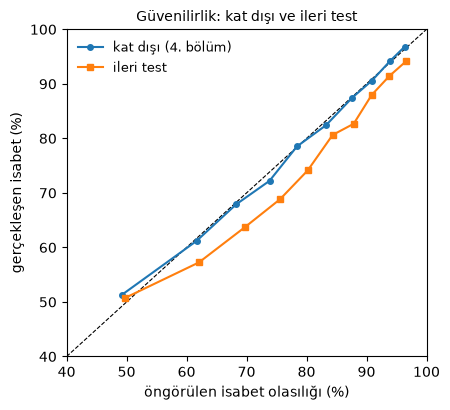

In [45]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([40, 100], [40, 100], "k--", lw=0.8)
ax.plot(deciles["predicted"], deciles["observed"], "o-", ms=4, label="kat dışı (4. bölüm)")
ax.plot(forward_reliability["deciles"]["predicted"], forward_reliability["deciles"]["observed"], "s-", ms=4,
        label="ileri test")
ax.set(xlabel="öngörülen isabet olasılığı (%)", ylabel="gerçekleşen isabet (%)", xlim=(40, 100), ylim=(40, 100))
ax.set_title("Güvenilirlik: kat dışı ve ileri test", fontsize=10)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Yeni ilanlar ortalamada tahminin üstünde duruyor. İsabet olasılığı yeni ilanlarda iyimser: ortalama
öngörü gerçekleşen paydan birkaç puan yüksek ve ileri testin güvenilirlik eğrisi en alt dilim dışında köşegenin
altında. Olasılık araçları yine ayırıyor: Brier skoru sabit öngörüden iyi ve "10'da N" büyüdükçe gerçekleşen isabet
genel olarak artıyor (en küçük N'lerde ilan az). Aralığın sonradan gelen ilanlarda %90'ın altında kalmasıyla aynı
durum: ikisi de aynı dönemin hatalarından kuruldu. Test ilanlarına bakıp düzeltmek ayar olurdu; yapılmadı.

## 7. Serbest metin

**Soru.** Satıcının ilan açıklaması tahmin modeline girmiyor (3. defter, 1.2). Girseydi kat dışı hata ne kadar
değişirdi?

**Açıklamalı koşum** (`free_text.oof_with_description`). Temel koşumun her şeyi aynı: katlar, öznitelikler, LightGBM
ayarları, erken durdurma. Her katın matrisine açıklamanın 50 kolonu eklenir: açıklama küçük harfe çevrilir
(`free_text.descriptions`; Türkçe I/ı ve İ/i ayrımıyla), kelime TF-IDF'ine (tek kelimeler ve iki kelimelik parçalar,
en az 5 ilanda geçenler) ve SVD ile 50 kolona çevrilir (`free_text.description_columns`); ikisi de yalnız katın
eğitim kısmından kurulur. Metinde kelime ya da kalıp aranmaz; açıklama yalnız sayısal kolonlara çevrilir. Ayarlar:

In [46]:
print("TF-IDF:", free_text.TFIDF, "| SVD boyutu:", free_text.TEXT_SVD)
texts = free_text.descriptions(listings)
print("Açıklaması boş ilan:", int((texts.str.strip() == "").sum()))

TF-IDF: {'analyzer': 'word', 'ngram_range': (1, 2), 'min_df': 5} | SVD boyutu: 50


Açıklaması boş ilan: 80


Önbellekten:

In [47]:
text_run = cache.load_or_run(free_text.oof_with_description, model_table, texts, cv_folds)
print("Açıklamalı koşumda ağaç, kat kat:", text_run["trees"], "| temel koşum:", base_trees)

Açıklamalı koşumda ağaç, kat kat: [535, 407, 391, 337, 281] | temel koşum: [274, 258, 212, 212, 307]


İki koşum log R², MAPE ve MAE ile; son satır metnin temel koşumun açıklayamadığı log varyanstan kapattığı pay:
(R²_metin − R²_temel) / (1 − R²_temel).

In [48]:
def log_r2(pred_log):
    """Log fiyat üzerinde R² (kat dışı)."""
    return 1 - ((log_price - pred_log) ** 2).sum() / ((log_price - log_price.mean()) ** 2).sum()


base_log = oof["pred_log"].to_numpy()
text_metrics = {name: {"r2_log": log_r2(run_log), **model.price_metrics(price, np.expm1(run_log))}
                for name, run_log in {"base": base_log, "text": text_run["pred_log"]}.items()}
text_table = pd.DataFrame(text_metrics).T[["r2_log", "mape", "mae"]]
text_table.loc["difference"] = text_table.loc["text"] - text_table.loc["base"]
unexplained_share = 100 * text_table.loc["difference", "r2_log"] / (1 - text_table.loc["base", "r2_log"])
print(f"Açıklanamayan log varyanstan kapanan pay: %{unexplained_share:.1f}")

text_table.round({"r2_log": 4, "mape": 2, "mae": 0}).astype({"mae": int}).rename(index={
    "base": "temel koşum", "text": "açıklamalı koşum", "difference": "fark (açıklamalı − temel)"}, columns={
    "r2_log": "R² (log fiyat)", "mape": "MAPE (%)", "mae": "MAE (₺)"}).rename_axis("koşum")

Açıklanamayan log varyanstan kapanan pay: %2.6


,R² (log fiyat),MAPE (%),MAE (₺)
koşum,,,
temel koşum,0.9699,6.49,109776
açıklamalı koşum,0.9707,6.41,108770
fark (açıklamalı − temel),0.0008,-0.08,-1006


Aynı fark kat kat: her katın kendi doğrulama ilanlarında açıklamalı koşumun MAPE'si eksi temel koşumunki.

In [49]:
text_by_fold = pd.Series({k: model.price_metrics(price[valid], np.expm1(text_run["pred_log"][valid]))["mape"]
                          - model.price_metrics(price[valid], np.expm1(base_log[valid]))["mape"]
                          for k, (_, valid) in enumerate(cv_folds, 1)})
text_by_fold.round(3).rename_axis("kat").rename("ΔMAPE (puan)").to_frame().T

kat,1,2,3,4,5
ΔMAPE (puan),-0.089,-0.081,-0.103,-0.059,-0.055


**Ne görüyoruz.** Açıklama eklenince üç ölçü de biraz iyileşiyor ve MAPE beş katın beşinde düşüyor. Kazanç küçük:
temel koşumun açıklayamadığı log varyansın küçük bir kısmı. Açıklamalı koşumda erken durdurma çoğu katta daha geç
duruyor.

**Ne gösterebilir, ne gösteremez.**

- Ölçülen fark açıklamanın taşıdığı her şeyi birlikte içeriyor; neyin katkı yaptığı ayrılmadı. Açıklamada kelime ya
  da kalıp aranmadı.
- Aynı araç başka bir ilan numarasıyla ve aynı açıklamayla yeniden yayımlanmışsa (1. defter, 1.5) ikizlerden biri
  eğitimde, öteki doğrulamada olabilir; açıklamalı koşum o ilanı ikizinin metninden tanıyabilir. Kazancın bir kısmı
  buradan gelebilir; bu defterde ölçülmedi.
- Tek koşum, tek tohum; kat farkları küçük ama hep aynı yönde.

Servis edilen tahmin modeli açıklama almıyor; bu bölüm yalnız dışarıda kalanın ne kadar olduğunu ölçüyor.

## Özet

- **Artıklar (1):** hataların çoğu küçük; yüzde hata ucuz araçta büyük, ₺ hata pahalı araçta. Tahminler fiyat
  düzeyine göre ortalamada bir yöne kaymıyor. %20 tanımı iki yönde eşit değil; iki yönü aynı oranla sayınca eksik ve
  fazla tahmin aşağı yukarı eşit.
- **Büyük hatalar (2):** emsalsiz ve az emsalli ilanlarda, yaşlı araçlarda ve F/S segmentinde sık; bu kırılımlar
  birbirinden ayrılmadı. En büyük ₺ hatalarının eksik tahminde toplanması ₺ ölçeğinin sonucu. Motor değeri tutarsız
  az sayıda ilan büyük hatanın açıklanabilir bir kaynağı.
- **%90 aralık (3):** tek pay genelde tutuyor ama gruplarda tutmuyor: yeni araçta geniş, yaşlı, ucuz ve emsalsiz
  araçta dar. Ölçek modeli payı araca göre ayarlıyor; gördüğü eksenlerin her grubunda hedefe yakın, görmediği
  eksenlerde tek paydan ne iyi ne kötü; aralığı çoğu ilanda daha dar ve aralık skoru daha iyi.
- **İsabet olasılığı (4):** "fiyat tahminin ±%10 yakınında" olasılığı kat dışında kalibre ve araçları ayırıyor.
- **Servis edilen aralık (5):** aynı tarif, s ve emsal bütün ilanlardan; emsal bulunamazsa pay genişliyor.
- **İleri test (6):** sonradan gelen ilanlarda hata biraz büyüyor, ama farkın çoğu o ilanların kendisinden. Aralık
  %90'ın birkaç puan altında, isabet olasılığı birkaç puan iyimser; ölçek modeli emsalsiz ilanlarda yine hedefe yakın.
- **Serbest metin (7):** açıklama tahmin modeline verilince hata biraz düşüyor; kazanç küçük ve servis edilen tahmin
  modelinde yok.

**Bu sayılar nasıl okunmalı.** %90 yaklaşık tutar ve yalnız aynı dönemin ilanları için: sonradan gelen ilanlarda
birkaç puan düşük (6). Ölçek modelinin yöntemi, ayarları, monotonluk kısıtı, alt sınırı ve ±%10 toleransı sonuçlar
görüldükten sonra kondu; hiçbirinde arama yapılmadı, ama elde bağımsız bir test de kalmadı. Fiyat seviyesi kayarsa dar
aralıklar kapsamayı ilk kaybeder (3.7). Tahmin modeli zamanı görmez; bu bir sınırlama, bu defterde analiz edilmiyor.
Kapsama ve isabet ilan fiyatı içindir, satış fiyatı için değil.

## Başlık sayıları

Defterin sayıları tek tabloda, her biri hesaplandığı bölümle. Tablo iki iş görüyor: sonuçları bir arada gösteriyor ve
defter yeniden çalıştırıldığında sayıların değişip değişmediği bu tablodan denetleniyor; bu yüzden kısa tutulmadı.
Anahtarlar kod adı olduğu için İngilizce; sayılar yukarıdaki tablolardaki gibi yuvarlandı.

In [50]:
rows = [
    ("oof_r2_price", float(round(summary["r2_price"], 4)), "kat dışı R², ₺ fiyat", "1.1"),
    ("oof_r2_log", float(round(summary["r2_log"], 4)), "kat dışı R², log fiyat", "1.1"),
    ("abs_resid_median_pct", float(round(spread["abs_median"], 2)), "|artık| medyanı (%)", "1.2"),
    ("within_10_pct", float(round(spread["within_10"], 2)), "|artık| ≤ %10 olan ilan (%)", "1.2"),
    ("sym_under_n", int(directions.loc["ratio_1_2", "under"]), "1,2 kat, iki yönde aynı: eksik tahmin (ilan)", "1.2"),
    ("q1_abs_resid_median_pct", float(round(by_quarter.loc["Q1", "median_abs_resid"], 2)),
     "en ucuz tahmin çeyreğinde |artık| medyanı (%)", "1.3"),
    ("q4_abs_resid_median_pct", float(round(by_quarter.loc["Q4", "median_abs_resid"], 2)),
     "en pahalı tahmin çeyreğinde |artık| medyanı (%)", "1.3"),
    ("calibration_slope", float(round(slope, 4)), "kalibrasyon eğimi", "1.3"),
    ("large_error_n", int(large.sum()), "büyük hata (ilan)", "2.1"),
    ("large_over_n", int(over.sum()), "büyük hata: fazla tahmin (ilan)", "2.1"),
    ("large_under_n", int(under.sum()), "büyük hata: eksik tahmin (ilan)", "2.1"),
    ("large_pct_single_cell", float(round(by_cell.loc["1", "large_pct"], 2)), "emsalsiz ilanda büyük hata (%)", "2.2"),
    ("large_pct_age_18_plus", float(round(100 * large[groups_2_3["age_18_plus"]].mean(), 2)),
     "18 yaş ve üstünde büyük hata (%)", "2.3"),
    ("large_pct_segment_f_s", float(round(100 * large[groups_2_3["segment_f_s"]].mean(), 2)),
     "F ya da S segmentinde büyük hata (%)", "2.3"),
    ("top100_under_n", int(ranking["under"]), "en büyük 100 ₺ hatasında eksik tahmin", "2.4"),
    ("top100_under_symmetric_mean", float(round(symmetric.mean(), 1)),
     "simetrik log hatayla beklenen eksik tahmin", "2.4"),
    ("spec_flagged_n", int(spec_table["flagged"]), "motor kuralının işaretlediği ilan", "2.5"),
    ("spec_flagged_abs_resid_median_pct", float(round(spec_table["flagged_median"], 2)),
     "işaretlilerde |artık| medyanı (%)", "2.5"),
    ("scale_k", float(round(k_all, 4)), "ölçek modelinin k'sı", "3.2"),
    ("single_coverage_pct", float(round(arms.loc["single", "coverage"], 2)), "tek pay: kapsama (%)", "3.3"),
    ("scale_coverage_pct", float(round(arms.loc["scale", "coverage"], 2)), "ölçek: kapsama (%)", "3.3"),
    ("scale_interval_score", float(round(arms.loc["scale", "interval_score"], 4)), "ölçek: aralık skoru", "3.3"),
    ("single_no_comparable_coverage_pct", float(round(arms.loc["single", "coverage_no_comparable"], 2)),
     "tek pay: emsalsizde kapsama (%)", "3.3"),
    ("scale_no_comparable_coverage_pct", float(round(arms.loc["scale", "coverage_no_comparable"], 2)),
     "ölçek: emsalsizde kapsama (%)", "3.3"),
    ("scale_width_median_pct", float(round(arms.loc["scale", "width_median"], 1)), "ölçek: genişlik medyanı (%)",
     "3.3"),
    ("single_input_groups_off_5", int(axis_summary.loc["single", "input_off_5"]),
     "tek pay: girdi eksenlerinde 5 puan sapan grup", "3.4"),
    ("scale_input_groups_off_5", int(axis_summary.loc["scale", "input_off_5"]),
     "ölçek: girdi eksenlerinde 5 puan sapan grup", "3.4"),
    ("narrow_fifth_scale_coverage_at_5pct_pct", float(round(shifted.loc[5, "narrow_scale"], 2)),
     "fiyatlar %5 yüksek olsaydı: en dar beşte birde ölçek kapsaması (%)", "3.7"),
    ("hit_mean_predicted_pct", float(round(reliability["mean_predicted"], 1)), "isabet: ortalama öngörülen (%)", "4"),
    ("hit_mean_observed_pct", float(round(reliability["mean_observed"], 1)), "isabet: gerçekleşen (%)", "4"),
    ("hit_brier_skill_pct", float(round(reliability["skill_pct"], 1)), "isabet: Brier iyileşmesi (%)", "4"),
    ("comparable_cells", int(served["cells"]), "emsal tablosunda hücre", "5"),
    ("forward_test_n", len(test), "ileri test: test ilanı", "6"),
    ("forward_trees", int(ahead["trees"]), "ileri test: ağaç sayısı", "6"),
    ("forward_mape", float(round(mape_table.loc["forward", "mape"], 2)), "ileri test: MAPE (%)", "6.1"),
    ("forward_oof_same_mape", float(round(mape_table.loc["oof_same", "mape"], 2)),
     "aynı ilanlarda kat dışı MAPE (%)", "6.1"),
    ("forward_mape_difference", float(round(mape_table.loc["difference", "mape"], 2)),
     "ileri test eksi kat dışı MAPE (puan)", "6.1"),
    ("forward_single_coverage_pct", float(round(forward_arms.loc["single", "coverage"], 2)),
     "ileri test: tek pay kapsaması (%)", "6.2"),
    ("forward_scale_coverage_pct", float(round(forward_arms.loc["scale", "coverage"], 2)),
     "ileri test: ölçek kapsaması (%)", "6.2"),
    ("forward_scale_no_comparable_coverage_pct", float(round(forward_arms.loc["scale", "coverage_no_comparable"], 2)),
     "ileri test: ölçek, emsalsizde kapsama (%)", "6.2"),
    ("forward_scale_k", float(round(k_forward, 4)), "ileri test: ölçek modelinin k'sı", "6.2"),
    ("forward_hit_mean_predicted_pct", float(round(forward_reliability["mean_predicted"], 1)),
     "ileri test: isabet, ortalama öngörülen (%)", "6.3"),
    ("forward_hit_mean_observed_pct", float(round(forward_reliability["mean_observed"], 1)),
     "ileri test: isabet, gerçekleşen (%)", "6.3"),
    ("text_r2_log", float(round(text_table.loc["text", "r2_log"], 4)), "açıklamalı koşum: R² (log fiyat)", "7"),
    ("text_mape", float(round(text_table.loc["text", "mape"], 2)), "açıklamalı koşum: MAPE (%)", "7"),
]
headline = {key: value for key, value, _, _ in rows}

headline_table = pd.DataFrame(rows, columns=["key", "value", "description", "section"], dtype=object).set_index("key")
headline_table[["value", "section", "description"]].rename_axis("anahtar").rename(
    columns={"value": "değer", "section": "bölüm", "description": "ne"})

,değer,bölüm,ne
anahtar,,,
oof_r2_price,0.9745,1.1,"kat dışı R², ₺ fiyat"
oof_r2_log,0.9699,1.1,"kat dışı R², log fiyat"
abs_resid_median_pct,4.68,1.2,|artık| medyanı (%)
within_10_pct,80.02,1.2,|artık| ≤ %10 olan ilan (%)
sym_under_n,812,1.2,"1,2 kat, iki yönde aynı: eksik tahmin (ilan)"
q1_abs_resid_median_pct,6.95,1.3,en ucuz tahmin çeyreğinde |artık| medyanı (%)
q4_abs_resid_median_pct,3.55,1.3,en pahalı tahmin çeyreğinde |artık| medyanı (%)
calibration_slope,1.0033,1.3,kalibrasyon eğimi
large_error_n,1208,2.1,büyük hata (ilan)
